# TP2 KASDAD - Regresi `threat_rank`

**EDA individual:** Apakah persentase laporan berlabel `artifact_signal = 1` berbeda antara `signal_stream` kosong dan terisi, setelah mempertimbangkan waktu dan volume laporan?

LightGBM L1 memakai fitur structured dan TF-IDF/SVD32, dengan rank blend yang dipilih melalui inner validation. Metrik utama: **MAE**.

Kelompok **A06 - KasdudLovers** | **Samuel Indriano** | NPM **2406400524**.

Notebook mencakup data, EDA, preprocessing, pemodelan, dan evaluasi temporal. Approach individual ini berbeda dari ensemble champion kelompok terbaru.

## 1. Persiapan dan data

Sediakan official `classification/Train.csv` untuk availability EDA dan `regression/Train.csv` untuk model. Letakkan keduanya di bawah `TP2_DATA_DIR` (default: `data/raw/` di current directory atau parent); `TP2_DATA_DIR` menunjuk folder yang berisi `classification/` dan `regression/`. Seluruh helper EDA, preprocessing, feature engineering, model, dan evaluasi custom berada di cell notebook ini; tidak ada impor dari file project lokal. Test inference tetap nonaktif.

Dependensi Python: NumPy, pandas, SciPy, scikit-learn, LightGBM, Matplotlib, threadpoolctl, IPython/Jupyter.

In [1]:
from __future__ import annotations
from pathlib import Path
import hashlib
import json
import os
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from threadpoolctl import threadpool_limits
from IPython.display import display

def find_data_root():
    configured = os.environ.get("TP2_DATA_DIR")
    if configured:
        root = Path(configured).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(f"TP2_DATA_DIR is not a directory: {root}")
        return root
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        for root in (candidate / "data" / "raw", candidate / "raw", candidate):
            if any((root / task).is_dir() for task in ("classification", "regression")):
                return root
    return current / "data" / "raw"

DATA_ROOT = find_data_root()

def task_files(task, root=None):
    if task not in {"classification", "regression"}:
        raise ValueError(f"Unknown task: {task}")
    folder = (Path(root) if root is not None else DATA_ROOT) / task
    files = {}
    for role, stem in (("train", "train"), ("test", "test"), ("sample", "samplesubmission")):
        matches = [p for p in folder.iterdir() if p.is_file() and p.suffix.lower() == ".csv" and p.stem.lower() == stem] if folder.is_dir() else []
        if len(matches) > 1:
            raise ValueError(f"Ambiguous {task}/{role}: {[p.name for p in matches]}")
        files[role] = matches[0] if matches else None
    return files

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

print("Python:", platform.python_version(), "| seed: 42 | thread limit: 2")
print("LightGBM:", __import__("lightgbm").__version__, "| data root:", DATA_ROOT)

Python: 3.13.5 | seed: 42 | thread limit: 2


LightGBM: 4.6.0 | data root: C:\Users\Sam\AppData\Local\Temp\samuel_root_standalone_najozsi2\data\raw


### Preprocessing dan definisi model

Fungsi berikut menangani format numerik, nilai kosong, kategori, representasi teks, dan model. Semua parameter preprocessing dipelajari dari data training pada fold yang bersangkutan. Kode tersedia langsung di sel dan dapat dibuka untuk diperiksa.

In [2]:
# Inline utility definitions; no repository modules are imported.
def _text_values(series: pd.Series) -> tuple[list[str], np.ndarray]:
    """Convert missing/blank stream entries to empty text and flag them."""
    values: list[str] = []
    missing = np.zeros(len(series), dtype=bool)
    for index, value in enumerate(series.to_numpy(dtype=object)):
        if _is_missing(value):
            values.append("")
            missing[index] = True
        else:
            text = str(value).strip()
            values.append(text)
            missing[index] = not bool(text)
    return values, missing

def stream_missing_mask(frame: pd.DataFrame | pd.Series) -> np.ndarray:
    """Return the Round 1 blank/missing semantics for ``signal_stream``."""
    if isinstance(frame, pd.DataFrame):
        if frame.columns.has_duplicates:
            raise ValueError("frame has duplicate feature columns")
        if "signal_stream" not in frame.columns:
            raise ValueError("frame must contain signal_stream")
        series = frame["signal_stream"]
    elif isinstance(frame, pd.Series):
        series = frame
    else:
        raise TypeError("frame must be a pandas DataFrame or Series")
    _, missing = _text_values(series)
    return missing.copy()

def array_digest(value):
    return hashlib.sha256(np.asarray(value,dtype='<f8').tobytes()).hexdigest()


In [3]:
# Inline availability EDA definitions; source SHA-256 2240da85704003ebeeb36b147ac01181f8f45da4e030af31c6cc7368dc2273d1.
"""Descriptive analysis helpers for Classification stream availability.

All contrasts are descriptive. Quantile boundaries are computed from
``text_load`` only; neither availability nor the outcome determines bins.
"""

from itertools import product
from typing import Iterable

import numpy as np
import pandas as pd

AVAILABILITY_ORDER = ("present", "missing")
PERIODS = ((47, 57, "47–57"), (58, 68, "58–68"), (69, 79, "69–79"))


def wilson_interval(successes: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    """Return a Wilson 95% interval for one binomial proportion."""
    if n <= 0 or successes < 0 or successes > n:
        raise ValueError("Wilson interval requires 0 <= successes <= n and n > 0")
    p = successes / n
    denominator = 1.0 + z * z / n
    center = (p + z * z / (2 * n)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denominator
    return float(max(0.0, center - half_width)), float(min(1.0, center + half_width))


def prepare_availability_frame(
    train: pd.DataFrame,
    stream_missing: Iterable[bool],
) -> pd.DataFrame:
    """Validate official raw columns and create a small analysis-only frame."""
    required = {"record_id", "cycle_code", "signal_stream", "text_load", "artifact_signal"}
    missing_columns = sorted(required - set(train.columns))
    if missing_columns:
        raise ValueError(f"Official Classification Train lacks columns: {missing_columns}")
    mask = np.asarray(list(stream_missing), dtype=bool)
    if len(mask) != len(train):
        raise ValueError("stream_missing must have one value per training row")
    if train["record_id"].isna().any() or train["record_id"].duplicated().any():
        raise ValueError("record_id must be complete and unique")
    target = pd.to_numeric(train["artifact_signal"], errors="raise")
    if target.isna().any() or not target.isin([0, 1]).all():
        raise ValueError("artifact_signal must be complete binary 0/1")
    cycle = pd.to_numeric(train["cycle_code"], errors="raise")
    if cycle.isna().any() or not np.equal(cycle, np.floor(cycle)).all():
        raise ValueError("cycle_code must be complete integer values")
    text_load = pd.to_numeric(train["text_load"], errors="raise")
    if text_load.isna().any() or not np.isfinite(text_load).all():
        raise ValueError("text_load must be complete and finite")

    period_labels = np.select(
        [cycle.between(start, end) for start, end, _ in PERIODS],
        [label for _, _, label in PERIODS],
        default="outside expected cycles",
    )
    if np.any(period_labels == "outside expected cycles"):
        raise ValueError("Train contains cycle_code outside the documented periods 47–79")
    return pd.DataFrame(
        {
            "record_id": train["record_id"].to_numpy(),
            "cycle_code": cycle.astype(int).to_numpy(),
            "period": period_labels,
            "text_load": text_load.astype(float).to_numpy(),
            "artifact_signal": target.astype(int).to_numpy(),
            "availability": np.where(mask, "missing", "present"),
        },
        index=train.index,
    )


def prevalence_table(frame: pd.DataFrame, group_columns: list[str]) -> pd.DataFrame:
    """Return denominators, positive counts, and proportions by requested groups."""
    if not group_columns:
        raise ValueError("At least one grouping column is required")
    grouped = (
        frame.groupby(group_columns, observed=True, dropna=False)
        .agg(n=("artifact_signal", "size"), positive=("artifact_signal", "sum"))
        .reset_index()
    )
    grouped["prevalence"] = grouped["positive"] / grouped["n"]
    return grouped


def add_global_quantile_bins(frame: pd.DataFrame, q: int) -> tuple[pd.DataFrame, np.ndarray]:
    """Add global, outcome-blind quantile bins of text_load and return edges."""
    if q < 2:
        raise ValueError("q must be at least 2")
    if frame["text_load"].isna().any():
        raise ValueError("text_load cannot be missing when creating bins")
    labels, edges = pd.qcut(frame["text_load"], q=q, labels=False, retbins=True, duplicates="raise")
    result = frame.copy()
    result[f"text_load_q{q}"] = labels.astype(int)
    return result, np.asarray(edges, dtype=float)


def standardized_contrast(
    frame: pd.DataFrame,
    strata: list[str],
    *,
    min_support: int = 20,
    availability_column: str = "availability",
    outcome_column: str = "artifact_signal",
) -> tuple[dict, pd.DataFrame]:
    """Standardize both availability rates to the same pooled supported-cell mix.

    Cells qualify only if both availability groups have at least ``min_support``
    observations. A common cell weight is its combined denominator divided by
    all rows in supported cells. The returned summary keeps group-specific
    support and coverage denominators explicit.
    """
    if not strata or min_support < 1:
        raise ValueError("strata must be non-empty and min_support positive")
    needed = set(strata) | {availability_column, outcome_column}
    if needed - set(frame.columns):
        raise ValueError(f"Missing columns for standardization: {sorted(needed - set(frame.columns))}")
    if frame[list(strata) + [availability_column, outcome_column]].isna().any().any():
        raise ValueError("strata, availability, and outcome must be complete")
    if not frame[availability_column].isin(AVAILABILITY_ORDER).all():
        raise ValueError("availability values must be 'present' or 'missing'")
    if not frame[outcome_column].isin([0, 1]).all():
        raise ValueError("outcome must be binary 0/1")

    aggregation = (
        frame.groupby(strata + [availability_column], observed=True, dropna=False)[outcome_column]
        .agg(n="size", positive="sum")
        .reset_index()
    )
    domains = []
    for column in strata:
        values = list(pd.unique(frame[column]))
        try:
            values = sorted(values)
        except TypeError:
            pass
        domains.append(values)
    # Build lookup without relying on pandas' namedtuple field behavior for
    # arbitrary column names such as a caller-provided stratum label.
    indexed = {}
    for _, row in aggregation.iterrows():
        key = tuple(row[column] for column in strata)
        indexed[(key, row[availability_column])] = (int(row["n"]), int(row["positive"]))

    rows = []
    for cell_key in product(*domains):
        cell = dict(zip(strata, cell_key))
        state = {}
        for availability in AVAILABILITY_ORDER:
            n, positive = indexed.get((cell_key, availability), (0, 0))
            state[availability] = {
                "n": n,
                "positive": positive,
                "prevalence": positive / n if n else np.nan,
            }
        combined_n = state["present"]["n"] + state["missing"]["n"]
        supported = all(state[name]["n"] >= min_support for name in AVAILABILITY_ORDER)
        rows.append(
            {
                **cell,
                "n_present": state["present"]["n"],
                "positive_present": state["present"]["positive"],
                "prevalence_present": state["present"]["prevalence"],
                "n_missing": state["missing"]["n"],
                "positive_missing": state["missing"]["positive"],
                "prevalence_missing": state["missing"]["prevalence"],
                "combined_n": combined_n,
                "supported": supported,
            }
        )
    cells = pd.DataFrame(rows)
    supported = cells.loc[cells["supported"]].copy()
    if supported.empty:
        raise ValueError("No strata meet minimum support for both availability groups")
    supported_rows = int(supported["combined_n"].sum())
    weighted = {}
    for availability in AVAILABILITY_ORDER:
        weighted[availability] = float(
            np.sum(
                (supported["combined_n"] / supported_rows)
                * supported[f"prevalence_{availability}"].to_numpy(dtype=float)
            )
        )
    total_by_group = {
        name: int(frame[availability_column].eq(name).sum()) for name in AVAILABILITY_ORDER
    }
    covered_by_group = {
        "present": int(supported["n_present"].sum()),
        "missing": int(supported["n_missing"].sum()),
    }
    summary = {
        "strata": strata,
        "minimum_n_per_availability_per_cell": int(min_support),
        "cells_total": int(len(cells)),
        "cells_supported": int(supported.shape[0]),
        "supported_rows_total": supported_rows,
        "coverage_all_rows": float(supported_rows / len(frame)),
        "covered_rows_by_availability": covered_by_group,
        "total_rows_by_availability": total_by_group,
        "coverage_by_availability": {
            name: float(covered_by_group[name] / total_by_group[name])
            for name in AVAILABILITY_ORDER
        },
        "standardized_prevalence": weighted,
        "standardized_missing_minus_present_pp": float(100 * (weighted["missing"] - weighted["present"])),
        "standardization_weight": "combined cell n divided by all rows in supported cells; same weights for both groups",
        "support_rule": "each supported cell has at least min_support rows in both availability groups",
    }
    return summary, cells


In [4]:
# Inline implementation from src/models/round1_models.py; source SHA-256 766e0c2e183c5aa653a5c5b81aae4d646e99cecdcd043bead3eadb99edd0a7a4.
"""Leakage-safe estimator wrappers for TP2 Regression Round 1.

The module deliberately implements only the preregistered baseline and model
families. It does not load data, split rows, train a full model, or write model
artifacts; the experiment runner owns those choices.
"""


import hashlib
import json
import math
import numbers
import re
from collections import Counter, defaultdict
from typing import Any

import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OrdinalEncoder, StandardScaler


TWO_FEATURES = ("impact_load", "entry_friction")
EXPANDED_FEATURES = (
    "impact_load",
    "entry_friction",
    "cycle_code",
    "scope_pressure",
    "text_load",
    "scope_trace",
    "org_spread",
    "module_spread",
    "telemetry_flag",
    "org_code",
    "module_code",
    "pattern_code",
)
NUMERIC_FEATURES = (
    "impact_load",
    "entry_friction",
    "cycle_code",
    "scope_pressure",
    "text_load",
)
MIXED_COUNT_FEATURES = ("scope_trace", "org_spread", "module_spread")
CATEGORICAL_FEATURES = ("org_code", "module_code", "pattern_code")
TELEMETRY_FEATURE = "telemetry_flag"
_KIND_NAMES = {"global_median", "impact_median", "joint_median", "linear", "hgb"}
_COUNT_TOKEN = re.compile(
    r"^\s*(?P<approx>~)?\s*(?P<number>\d+(?:\.\d+)?)\s*(?P<unit>.*?)\s*$"
)
_TELEMETRY_MAP = {
    "inactive": 0.0,
    "false": 0.0,
    "n": 0.0,
    "0": 0.0,
    "active": 1.0,
    "true": 1.0,
    "y": 1.0,
    "1": 1.0,
}
_FIXED_HGB_PARAMS: dict[str, Any] = {
    "learning_rate": 0.05,
    "max_iter": 200,
    "max_leaf_nodes": 15,
    "min_samples_leaf": 30,
    "l2_regularization": 1.0,
    "max_bins": 255,
    "early_stopping": False,
    "random_state": 42,
}


def _is_missing(value: Any) -> bool:
    try:
        return bool(pd.isna(value))
    except (TypeError, ValueError):
        return False


def _number_array(series: pd.Series) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return numeric values, missing flags, and invalid-format flags."""
    missing = series.map(_is_missing).to_numpy(dtype=bool)
    text_blank = series.map(lambda value: isinstance(value, str) and not value.strip()).to_numpy(dtype=bool)
    missing |= text_blank
    numeric = pd.to_numeric(series.mask(missing), errors="coerce").to_numpy(dtype=float)
    finite = np.isfinite(numeric)
    invalid = (~missing) & (~finite)
    numeric[~finite] = np.nan
    return numeric, missing.astype(float), invalid.astype(float)


def _mixed_count_arrays(
    series: pd.Series,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Parse counts without guessing; only numbers and an optional ``nodes`` unit are accepted."""
    n = len(series)
    value = np.full(n, np.nan, dtype=float)
    approximate = np.zeros(n, dtype=float)
    suffix_present = np.zeros(n, dtype=float)
    parse_fail = np.zeros(n, dtype=float)
    missing = np.zeros(n, dtype=float)
    for position, raw in enumerate(series.to_numpy(dtype=object)):
        if _is_missing(raw) or (isinstance(raw, str) and not raw.strip()):
            missing[position] = 1.0
            continue
        match = _COUNT_TOKEN.fullmatch(str(raw))
        if match is None:
            parse_fail[position] = 1.0
            continue
        unit = match.group("unit").strip().casefold()
        suffix_present[position] = float(bool(unit))
        if unit not in {"", "nodes"}:
            parse_fail[position] = 1.0
            continue
        parsed = float(match.group("number"))
        if not math.isfinite(parsed):
            parse_fail[position] = 1.0
            continue
        value[position] = parsed
        approximate[position] = float(match.group("approx") is not None)
    return value, approximate, suffix_present, parse_fail, missing


def _telemetry_arrays(series: pd.Series) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Map the observed binary spellings and retain unknown/missing flags."""
    n = len(series)
    value = np.full(n, np.nan, dtype=float)
    unknown = np.zeros(n, dtype=float)
    missing = np.zeros(n, dtype=float)
    for position, raw in enumerate(series.to_numpy(dtype=object)):
        if _is_missing(raw) or (isinstance(raw, str) and not raw.strip()):
            missing[position] = 1.0
            continue
        normalized = str(raw).strip().casefold()
        if normalized not in _TELEMETRY_MAP:
            unknown[position] = 1.0
            continue
        value[position] = _TELEMETRY_MAP[normalized]
    return value, unknown, missing


def _category_array(series: pd.Series) -> np.ndarray:
    normalized = np.empty(len(series), dtype=object)
    for position, raw in enumerate(series.to_numpy(dtype=object)):
        if _is_missing(raw) or (isinstance(raw, str) and not raw.strip()):
            normalized[position] = np.nan
        else:
            normalized[position] = str(raw).strip()
    return normalized


def _to_builtin(value: Any) -> Any:
    """Convert audit metadata to JSON-safe Python scalars and containers."""
    if isinstance(value, dict):
        return {str(key): _to_builtin(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [_to_builtin(item) for item in value]
    if isinstance(value, np.ndarray):
        return [_to_builtin(item) for item in value.tolist()]
    if isinstance(value, np.generic):
        return _to_builtin(value.item())
    if isinstance(value, float) and not math.isfinite(value):
        return None
    if isinstance(value, (str, int, float, bool)) or value is None:
        return value
    return str(value)


def _fingerprint_value(value: Any) -> str:
    if _is_missing(value):
        return "null"
    if isinstance(value, (bool, np.bool_)):
        return "bool:" + ("1" if value else "0")
    if isinstance(value, numbers.Integral):
        return f"int:{int(value)}"
    if isinstance(value, numbers.Real):
        value_float = float(value)
        if not math.isfinite(value_float):
            return "float:" + repr(value_float)
        return "float:" + value_float.hex()
    return "str:" + str(value)


def _fit_fingerprint(X: pd.DataFrame, feature_names: tuple[str, ...], y: np.ndarray) -> str:
    """Hash the exact selected training inputs and target without retaining rows."""
    digest = hashlib.sha256()

    def add_text(text: str) -> None:
        encoded = text.encode("utf-8", errors="surrogatepass")
        digest.update(len(encoded).to_bytes(8, "big"))
        digest.update(encoded)

    add_text(json.dumps(feature_names, ensure_ascii=False, separators=(",", ":")))
    add_text(str(len(X)))
    for column in feature_names:
        for value in X[column].to_numpy(dtype=object):
            add_text(_fingerprint_value(value))
    for value in y:
        add_text(_fingerprint_value(float(value)))
    return digest.hexdigest()


def _validate_dataframe(X: pd.DataFrame) -> None:
    if not isinstance(X, pd.DataFrame):
        raise TypeError("X must be a pandas DataFrame so feature names can be audited")
    if X.columns.has_duplicates:
        raise ValueError("X has duplicate column names")


def _target_array(y: Any, expected_rows: int) -> np.ndarray:
    target = np.asarray(y)
    if target.ndim != 1:
        raise ValueError("y must be one-dimensional")
    if len(target) != expected_rows:
        raise ValueError("X and y row counts differ")
    try:
        target = target.astype(float)
    except (TypeError, ValueError) as exc:
        raise ValueError("y must contain numeric regression targets") from exc
    if not np.isfinite(target).all():
        raise ValueError("y must be finite and non-missing")
    if expected_rows == 0:
        raise ValueError("Cannot fit on an empty training set")
    return target


class _HGBPreprocessor:
    """Training-fold-fitted numeric imputation and native categorical encoding."""

    def __init__(self, feature_preset: str):
        self.feature_preset = feature_preset
        self.encoder: OrdinalEncoder | None = None
        self.medians: dict[str, float] = {}
        self.transformed_feature_names: list[str] = []
        self.numeric_feature_names: list[str] = []
        self.categorical_positions: list[int] = []
        self.category_counts: dict[str, dict[str, Any]] = {}
        self.seen_categories: dict[str, set[str]] = {}

    def _raw_matrix(
        self, X: pd.DataFrame, *, fit_categories: bool
    ) -> tuple[np.ndarray, list[str], list[str], list[str], dict[str, np.ndarray], dict[str, np.ndarray]]:
        if self.feature_preset == "two":
            columns: list[np.ndarray] = []
            names: list[str] = []
            for feature in TWO_FEATURES:
                values, missing, invalid = _number_array(X[feature])
                if np.any(missing) or np.any(invalid):
                    raise ValueError(f"two-feature HGB requires complete numeric {feature!r} values")
                columns.append(values)
                names.append(feature)
            return np.column_stack(columns), names, names.copy(), [], {}, {}

        numeric_columns: list[np.ndarray] = []
        numeric_names: list[str] = []
        categorical_columns: list[np.ndarray] = []
        categorical_names: list[str] = []
        category_raw: dict[str, np.ndarray] = {}
        category_missing: dict[str, np.ndarray] = {}
        for feature in EXPANDED_FEATURES:
            if feature in NUMERIC_FEATURES:
                values, missing, invalid = _number_array(X[feature])
                numeric_columns.extend((values, invalid, missing))
                numeric_names.extend((feature, f"{feature}__parsefail", f"{feature}__missing"))
            elif feature in MIXED_COUNT_FEATURES:
                values, approximate, suffix_present, invalid, missing = _mixed_count_arrays(X[feature])
                numeric_columns.extend((values, approximate, suffix_present, invalid, missing))
                numeric_names.extend(
                    (
                        feature,
                        f"{feature}__approximate",
                        f"{feature}__suffix_present",
                        f"{feature}__parsefail",
                        f"{feature}__missing",
                    )
                )
            elif feature == TELEMETRY_FEATURE:
                values, unknown, missing = _telemetry_arrays(X[feature])
                numeric_columns.extend((values, unknown, missing))
                numeric_names.extend(
                    (feature, f"{feature}__unknown", f"{feature}__missing")
                )
            elif feature in CATEGORICAL_FEATURES:
                raw = _category_array(X[feature])
                category_raw[feature] = raw
                category_missing[feature] = np.array(
                    [value is np.nan or _is_missing(value) for value in raw], dtype=float
                )
                categorical_columns.append(raw)
                categorical_names.append(feature)

        if fit_categories:
            self.encoder = OrdinalEncoder(
                min_frequency=30,
                max_categories=254,
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                encoded_missing_value=-1,
                dtype=np.float64,
            )
            category_matrix = np.column_stack(categorical_columns)
            self.encoder.fit(category_matrix)
            for index, feature in enumerate(categorical_names):
                categories = self.encoder.categories_[index]
                seen = {
                    str(value)
                    for value in categories
                    if not _is_missing(value)
                }
                self.seen_categories[feature] = seen

        if categorical_columns:
            if self.encoder is None:
                raise RuntimeError("Categorical encoder was not fitted")
            encoded = self.encoder.transform(np.column_stack(categorical_columns))
        else:
            encoded = np.empty((len(X), 0), dtype=float)

        matrix_columns: list[np.ndarray] = []
        all_names: list[str] = []
        numeric_output_names: list[str] = []
        categorical_positions: list[int] = []
        numeric_index = 0
        categorical_index = 0
        for feature in EXPANDED_FEATURES:
            if feature in NUMERIC_FEATURES:
                for _ in range(3):
                    matrix_columns.append(numeric_columns[numeric_index])
                    all_names.append(numeric_names[numeric_index])
                    numeric_output_names.append(numeric_names[numeric_index])
                    numeric_index += 1
            elif feature in MIXED_COUNT_FEATURES:
                for _ in range(5):
                    matrix_columns.append(numeric_columns[numeric_index])
                    all_names.append(numeric_names[numeric_index])
                    numeric_output_names.append(numeric_names[numeric_index])
                    numeric_index += 1
            elif feature == TELEMETRY_FEATURE:
                for _ in range(3):
                    matrix_columns.append(numeric_columns[numeric_index])
                    all_names.append(numeric_names[numeric_index])
                    numeric_output_names.append(numeric_names[numeric_index])
                    numeric_index += 1
            elif feature in CATEGORICAL_FEATURES:
                categorical_positions.append(len(all_names))
                matrix_columns.append(encoded[:, categorical_index])
                all_names.append(f"{feature}__ordinal")
                categorical_index += 1
                matrix_columns.append(category_missing[feature])
                all_names.append(f"{feature}__missing")
                numeric_output_names.append(f"{feature}__missing")

        matrix = np.column_stack(matrix_columns).astype(float, copy=False)
        if fit_categories:
            for index, feature in enumerate(categorical_names):
                raw = category_raw[feature]
                observed = [str(value) for value in raw if not _is_missing(value)]
                freq = Counter(observed)
                encoded_train = encoded[:, index]
                represented = np.unique(encoded_train[encoded_train >= 0])
                infrequent = getattr(self.encoder, "infrequent_categories_", None)
                infrequent_count = 0
                if infrequent is not None and infrequent[index] is not None:
                    infrequent_count = len(infrequent[index])
                self.category_counts[feature] = {
                    "observed_unique": len(freq),
                    "encoded_categories": int(len(represented)),
                    "infrequent_categories": int(infrequent_count),
                    "training_missing_rows": int(sum(_is_missing(value) for value in raw)),
                    "training_rows": len(raw),
                    "min_frequency": 30,
                    "max_categories": 254,
                }
        return matrix, all_names, numeric_output_names, categorical_names, category_raw, category_missing

    def fit_transform(self, X: pd.DataFrame) -> tuple[np.ndarray, list[bool]]:
        matrix, names, numeric_names, _, _, _ = self._raw_matrix(X, fit_categories=True)
        self.transformed_feature_names = names
        self.numeric_feature_names = numeric_names
        categorical_name_set = {f"{name}__ordinal" for name in CATEGORICAL_FEATURES}
        self.categorical_positions = [
            position for position, name in enumerate(names) if name in categorical_name_set
        ]
        numeric_positions = [
            position for position, name in enumerate(names) if name not in categorical_name_set
        ]
        self.medians = {}
        for position in numeric_positions:
            column = matrix[:, position]
            finite = column[np.isfinite(column)]
            median = float(np.median(finite)) if len(finite) else 0.0
            self.medians[names[position]] = median
            column[~np.isfinite(column)] = median
        categorical_mask = [position in self.categorical_positions for position in range(len(names))]
        return matrix, categorical_mask

    def transform(self, X: pd.DataFrame) -> tuple[np.ndarray, dict[str, int]]:
        matrix, names, _, categorical_names, category_raw, _ = self._raw_matrix(
            X, fit_categories=False
        )
        if names != self.transformed_feature_names:
            raise RuntimeError("Transformed feature schema changed after fit")
        unknown_counts: dict[str, int] = {}
        for feature in categorical_names:
            raw = category_raw[feature]
            seen = self.seen_categories[feature]
            unknown_counts[feature] = int(
                sum(not _is_missing(value) and str(value) not in seen for value in raw)
            )
        categorical_set = set(self.categorical_positions)
        for position, name in enumerate(names):
            if position in categorical_set:
                continue
            column = matrix[:, position]
            column[~np.isfinite(column)] = self.medians[name]
        return matrix, unknown_counts

    def audit_state(self) -> dict[str, Any]:
        return {
            "transformed_feature_names": list(self.transformed_feature_names),
            "numeric_imputer_medians": dict(self.medians),
            "categorical_feature_names": [
                self.transformed_feature_names[position]
                for position in self.categorical_positions
            ],
            "category_counts": dict(self.category_counts),
            "ordinal_encoder": {
                "min_frequency": 30,
                "max_categories": 254,
                "handle_unknown": "use_encoded_value",
                "unknown_value": -1,
                "encoded_missing_value": -1,
                "dtype": "float64",
            },
        }


class Round1Model:
    """Small estimator-compatible wrapper with reproducible audit metadata."""

    def __init__(self, recipe: dict[str, Any]):
        if not isinstance(recipe, dict):
            raise TypeError("recipe must be a dictionary")
        unknown_keys = set(recipe) - {"id", "kind", "features", "min_support", "params"}
        if unknown_keys:
            raise ValueError(f"Unsupported recipe fields: {sorted(unknown_keys)}")
        self.model_id = str(recipe.get("id", "round1"))
        self.kind = recipe.get("kind")
        if self.kind not in _KIND_NAMES:
            raise ValueError(f"kind must be one of {sorted(_KIND_NAMES)}")
        self.feature_preset = recipe.get("features", "two")
        if self.feature_preset not in {"two", "expanded"}:
            raise ValueError("features must be 'two' or 'expanded'")
        if self.kind == "linear" and self.feature_preset != "two":
            raise ValueError("linear is restricted to the two numeric features")
        self.min_support = recipe.get("min_support", 30)
        if not isinstance(self.min_support, numbers.Integral) or int(self.min_support) != 30:
            raise ValueError("Round 1 lookup baselines use the frozen support threshold 30")
        self.min_support = int(self.min_support)
        params = recipe.get("params", {})
        if not isinstance(params, dict):
            raise TypeError("params must be a dictionary")
        self.hgb_params: dict[str, Any] = {}
        if self.kind == "hgb":
            allowed = set(_FIXED_HGB_PARAMS) | {"loss", "interaction_cst"}
            unsupported = set(params) - allowed
            if unsupported:
                raise ValueError(f"Unsupported HGB parameters: {sorted(unsupported)}")
            loss = params.get("loss", "squared_error")
            if loss not in {"squared_error", "absolute_error"}:
                raise ValueError("HGB loss must be squared_error or absolute_error")
            for name, fixed_value in _FIXED_HGB_PARAMS.items():
                if name in params and params[name] != fixed_value:
                    raise ValueError(f"HGB {name} is frozen at {fixed_value!r}")
            interaction = params.get("interaction_cst", None)
            if interaction not in {None, "no_interactions"}:
                raise ValueError("interaction_cst may only be None or 'no_interactions'")
            self.hgb_params = {**_FIXED_HGB_PARAMS, "loss": loss}
            if interaction is not None:
                self.hgb_params["interaction_cst"] = interaction
        elif params:
            raise ValueError("Only HGB recipes accept model parameters")
        self._fitted = False
        self._state: dict[str, Any] = {}
        self._prediction_diagnostics: dict[str, Any] = {}

    def _required_feature_names(self) -> tuple[str, ...]:
        if self.kind == "global_median":
            return ()
        if self.kind == "impact_median":
            return ("impact_load",)
        if self.kind == "joint_median":
            return TWO_FEATURES
        return TWO_FEATURES if self.feature_preset == "two" else EXPANDED_FEATURES

    def _selected(self, X: pd.DataFrame) -> pd.DataFrame:
        _validate_dataframe(X)
        names = self._required_feature_names()
        missing = [name for name in names if name not in X.columns]
        if missing:
            raise ValueError(f"X is missing required feature columns: {missing}")
        return X.loc[:, list(names)]

    @staticmethod
    def _group_component(value: Any) -> float | None:
        if _is_missing(value):
            return None
        try:
            parsed = float(value)
        except (TypeError, ValueError):
            return None
        return parsed if math.isfinite(parsed) else None

    def _fit_lookup(self, X: pd.DataFrame, y: np.ndarray) -> None:
        self._global_median = float(np.median(y))
        self._group_medians: dict[tuple[float, ...], float] = {}
        self._group_counts: dict[tuple[float, ...], int] = {}
        self._impact_medians: dict[tuple[float, ...], float] = {}
        self._impact_counts: dict[tuple[float, ...], int] = {}
        self._entry_medians: dict[tuple[float, ...], float] = {}
        self._entry_counts: dict[tuple[float, ...], int] = {}

        def summarize(columns: tuple[str, ...]) -> tuple[dict[tuple[float, ...], float], dict[tuple[float, ...], int]]:
            values: dict[tuple[float, ...], list[float]] = defaultdict(list)
            for row, target in zip(X.loc[:, list(columns)].itertuples(index=False, name=None), y):
                key_values = tuple(self._group_component(value) for value in row)
                if any(value is None for value in key_values):
                    continue
                key = tuple(float(value) for value in key_values if value is not None)
                values[key].append(float(target))
            counts = {key: len(group_y) for key, group_y in values.items()}
            medians = {key: float(np.median(group_y)) for key, group_y in values.items()}
            return medians, counts

        if self.kind == "impact_median":
            all_medians, all_counts = summarize(("impact_load",))
            kept = {key for key, count in all_counts.items() if count >= self.min_support}
            self._group_medians = {key: value for key, value in all_medians.items() if key in kept}
            self._group_counts = {key: all_counts[key] for key in kept}
        elif self.kind == "joint_median":
            joint_medians, joint_counts = summarize(TWO_FEATURES)
            impact_medians, impact_counts = summarize(("impact_load",))
            entry_medians, entry_counts = summarize(("entry_friction",))
            self._group_medians = {
                key: value for key, value in joint_medians.items() if joint_counts[key] >= self.min_support
            }
            self._group_counts = {
                key: count for key, count in joint_counts.items() if count >= self.min_support
            }
            self._impact_medians = {
                key: value for key, value in impact_medians.items() if impact_counts[key] >= self.min_support
            }
            self._impact_counts = {
                key: count for key, count in impact_counts.items() if count >= self.min_support
            }
            self._entry_medians = {
                key: value for key, value in entry_medians.items() if entry_counts[key] >= self.min_support
            }
            self._entry_counts = {
                key: count for key, count in entry_counts.items() if count >= self.min_support
            }

    def fit(self, X: pd.DataFrame, y: Any) -> "Round1Model":
        selected = self._selected(X)
        target = _target_array(y, len(selected))
        feature_names = tuple(selected.columns)
        fingerprint = _fit_fingerprint(selected, feature_names, target)
        self._fit_rows = len(target)
        self._fit_fingerprint = fingerprint
        self._input_feature_names = list(feature_names)
        self._transformed_feature_names: list[str] = []
        self._imputer_medians: dict[str, float] = {}
        self._category_counts: dict[str, dict[str, Any]] = {}
        self._hyperparameters: dict[str, Any] = {}

        if self.kind in {"global_median", "impact_median", "joint_median"}:
            self._fit_lookup(selected, target)
            self._transformed_feature_names = list(feature_names)
            self._hyperparameters = {"kind": self.kind, "min_support": self.min_support}
        elif self.kind == "linear":
            numeric = np.column_stack(
                [_number_array(selected[name])[0] for name in TWO_FEATURES]
            )
            missing = ~np.isfinite(numeric)
            if np.any(missing):
                raise ValueError("linear requires complete numeric impact_load and entry_friction")
            self._scaler = StandardScaler()
            scaled = self._scaler.fit_transform(numeric)
            self._estimator = LinearRegression()
            self._estimator.fit(scaled, target)
            self._transformed_feature_names = list(TWO_FEATURES)
            self._hyperparameters = {
                "estimator": "LinearRegression",
                "fit_intercept": True,
                "scaler": "StandardScaler",
                "scaler_with_mean": True,
                "scaler_with_std": True,
            }
        elif self.kind == "hgb":
            self._preprocessor = _HGBPreprocessor(self.feature_preset)
            matrix, categorical_mask = self._preprocessor.fit_transform(selected)
            actual_params = dict(self.hgb_params)
            actual_params["categorical_features"] = categorical_mask if any(categorical_mask) else None
            self._estimator = HistGradientBoostingRegressor(**actual_params)
            self._estimator.fit(matrix, target)
            self._transformed_feature_names = list(self._preprocessor.transformed_feature_names)
            self._imputer_medians = dict(self._preprocessor.medians)
            self._category_counts = dict(self._preprocessor.category_counts)
            self._hyperparameters = {
                key: _to_builtin(value)
                for key, value in self._estimator.get_params(deep=False).items()
            }
        self._fitted = True
        self._prediction_diagnostics = {"n_predictions": 0}
        return self

    def _predict_lookup(self, X: pd.DataFrame) -> np.ndarray:
        predictions = np.full(len(X), self._global_median, dtype=float)
        fallback_counts: Counter[str] = Counter()
        if self.kind == "global_median":
            fallback_counts["global"] = len(X)
            self._prediction_diagnostics = {
                "n_predictions": int(len(X)),
                "fallback_counts": dict(sorted(fallback_counts.items())),
            }
            return predictions
        for position, row in enumerate(X.itertuples(index=False, name=None)):
            if self.kind == "impact_median":
                impact = self._group_component(row[0])
                key = None if impact is None else (impact,)
                if key in self._group_medians:
                    predictions[position] = self._group_medians[key]
                    fallback_counts["impact"] += 1
                else:
                    fallback_counts["global"] += 1
                continue

            impact = self._group_component(row[0])
            entry = self._group_component(row[1])
            joint_key = None if impact is None or entry is None else (impact, entry)
            impact_key = None if impact is None else (impact,)
            entry_key = None if entry is None else (entry,)
            if joint_key in self._group_medians:
                predictions[position] = self._group_medians[joint_key]
                fallback_counts["joint"] += 1
            elif impact_key in self._impact_medians:
                predictions[position] = self._impact_medians[impact_key]
                fallback_counts["impact"] += 1
            elif entry_key in self._entry_medians:
                predictions[position] = self._entry_medians[entry_key]
                fallback_counts["entry_friction"] += 1
            else:
                fallback_counts["global"] += 1
        self._prediction_diagnostics = {
            "n_predictions": int(len(X)),
            "fallback_counts": dict(sorted(fallback_counts.items())),
        }
        return predictions

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        if not self._fitted:
            raise RuntimeError("Model must be fitted before predict")
        selected = self._selected(X)
        if self.kind in {"global_median", "impact_median", "joint_median"}:
            return self._predict_lookup(selected)
        if self.kind == "linear":
            numeric = np.column_stack(
                [_number_array(selected[name])[0] for name in TWO_FEATURES]
            )
            if not np.isfinite(numeric).all():
                raise ValueError("linear requires complete numeric impact_load and entry_friction")
            predictions = self._estimator.predict(self._scaler.transform(numeric))
            self._prediction_diagnostics = {"n_predictions": int(len(selected))}
            return np.asarray(predictions, dtype=float)
        matrix, unknown_counts = self._preprocessor.transform(selected)
        predictions = self._estimator.predict(matrix)
        self._prediction_diagnostics = {
            "n_predictions": int(len(selected)),
            "unknown_category_rows": dict(sorted(unknown_counts.items())),
        }
        return np.asarray(predictions, dtype=float)

    def prediction_diagnostics(self) -> dict[str, Any]:
        return json.loads(json.dumps(_to_builtin(self._prediction_diagnostics), sort_keys=True))

    def audit_state(self) -> dict[str, Any]:
        if not self._fitted:
            raise RuntimeError("Model must be fitted before audit_state")
        state: dict[str, Any] = {
            "id": self.model_id,
            "kind": self.kind,
            "feature_preset": self.feature_preset,
            "input_feature_names": list(self._input_feature_names),
            "transformed_feature_names": list(self._transformed_feature_names),
            "fit_rows": int(self._fit_rows),
            "fit_data_sha256": self._fit_fingerprint,
            "sklearn_version": sklearn.__version__,
            "actual_hyperparameters": self._hyperparameters,
            "prediction_diagnostics": self._prediction_diagnostics,
        }
        if self.kind in {"global_median", "impact_median", "joint_median"}:
            state["min_support"] = self.min_support
            state["global_target_median"] = self._global_median
            state["supported_group_counts"] = {
                "primary": len(self._group_counts),
                "impact": len(self._impact_counts),
                "entry_friction": len(self._entry_counts),
            }

            def entries(
                medians: dict[tuple[float, ...], float], counts: dict[tuple[float, ...], int]
            ) -> list[dict[str, Any]]:
                return [
                    {"key": list(key), "rows": int(counts[key]), "median": medians[key]}
                    for key in sorted(medians)
                ]

            state["learned_group_medians"] = {
                "primary": entries(self._group_medians, self._group_counts),
                "impact": entries(self._impact_medians, self._impact_counts),
                "entry_friction": entries(self._entry_medians, self._entry_counts),
            }
        elif self.kind == "linear":
            state["standard_scaler"] = {
                "mean": self._scaler.mean_.tolist(),
                "scale": self._scaler.scale_.tolist(),
                "variance": self._scaler.var_.tolist(),
            }
            state["linear_coefficients"] = self._estimator.coef_.tolist()
            state["linear_intercept"] = float(self._estimator.intercept_)
        elif self.kind == "hgb":
            state["numeric_imputer_medians"] = dict(self._imputer_medians)
            state["category_counts"] = dict(self._category_counts)
            state["ordinal_encoder"] = self._preprocessor.audit_state()["ordinal_encoder"]
        return json.loads(json.dumps(_to_builtin(state), sort_keys=True))


def build_model(recipe: dict[str, Any]) -> Round1Model:
    """Build an unfitted Round 1 estimator from the runner's explicit recipe."""
    return Round1Model(recipe)


__all__ = [
    "CATEGORICAL_FEATURES",
    "EXPANDED_FEATURES",
    "MIXED_COUNT_FEATURES",
    "TWO_FEATURES",
    "Round1Model",
    "build_model",
]


# Keep the original notebook's descriptive alias for the baseline model builder.
build_round1_model = build_model


In [5]:
# Inline implementation from src/models/regression_round2_models.py; source SHA-256 f56f7ee2c337acdf2cbe7160719faf62b1e3d3470a7f656b044ce0890d677e09.
"""Controlled Regression Round 2 HGB feature-set adapters.

This module reuses the frozen Round 1 HGB objective and parser contracts. Round
2 variants may select only explicit Round 1 eligible structured source columns;
all transforms and category vocabularies are learned from fit rows only.
"""

import hashlib
import json
from typing import Any, Iterable

import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder
from collections import Counter



def _params() -> dict[str, Any]:
    return {**_FIXED_HGB_PARAMS, "loss": "absolute_error"}


def _tree_complexity(estimator: HistGradientBoostingRegressor) -> dict[str, Any]:
    predictors = getattr(estimator, "_predictors", [])
    nodes = [tree.nodes for iteration in predictors for tree in iteration]
    node_counts = [int(len(array)) for array in nodes]
    leaf_counts = [int(np.count_nonzero(array["is_leaf"])) for array in nodes]
    return {
        "iterations_fitted": int(len(predictors)),
        "trees_fitted": int(len(nodes)),
        "total_nodes": int(sum(node_counts)),
        "total_leaves": int(sum(leaf_counts)),
        "node_counts_per_tree": node_counts,
        "leaf_counts_per_tree": leaf_counts,
    }


def _tree_digest(estimator: HistGradientBoostingRegressor) -> str:
    digest = hashlib.sha256()
    for iteration in getattr(estimator, "_predictors", []):
        for tree in iteration:
            nodes = tree.nodes
            digest.update(repr((nodes.dtype.descr, nodes.shape)).encode("utf-8"))
            digest.update(nodes.tobytes())
    baseline = np.asarray(getattr(estimator, "_baseline_prediction", []), dtype=np.float64)
    digest.update(repr((baseline.dtype.str, baseline.shape)).encode("ascii"))
    digest.update(baseline.tobytes())
    return digest.hexdigest()


class _SelectedPreprocessor:
    """Round 1-compatible transform over an explicitly selected source subset."""

    def __init__(self, selected_features: tuple[str, ...]):
        self.selected_features = selected_features
        self.encoder: OrdinalEncoder | None = None
        self.medians: dict[str, float] = {}
        self.transformed_feature_names: list[str] = []
        self.numeric_feature_names: list[str] = []
        self.categorical_positions: list[int] = []
        self.category_counts: dict[str, dict[str, Any]] = {}
        self.seen_categories: dict[str, set[str]] = {}
        self.category_names = tuple(name for name in selected_features if name in CATEGORICAL_FEATURES)

    def _matrix(self, X: pd.DataFrame, *, fit_categories: bool):
        # X was sliced to the explicit selected-feature allowlist by the wrapper.
        numeric: dict[str, list[np.ndarray]] = {}
        numeric_names: dict[str, list[str]] = {}
        category_raw: dict[str, np.ndarray] = {}
        category_missing: dict[str, np.ndarray] = {}
        for feature in self.selected_features:
            if feature in NUMERIC_FEATURES:
                values, missing, invalid = _number_array(X[feature])
                numeric[feature] = [values, invalid, missing]
                numeric_names[feature] = [feature, f"{feature}__parsefail", f"{feature}__missing"]
            elif feature in MIXED_COUNT_FEATURES:
                values, approximate, suffix, invalid, missing = _mixed_count_arrays(X[feature])
                numeric[feature] = [values, approximate, suffix, invalid, missing]
                numeric_names[feature] = [feature, f"{feature}__approximate", f"{feature}__suffix_present",
                                          f"{feature}__parsefail", f"{feature}__missing"]
            elif feature == TELEMETRY_FEATURE:
                values, unknown, missing = _telemetry_arrays(X[feature])
                numeric[feature] = [values, unknown, missing]
                numeric_names[feature] = [feature, f"{feature}__unknown", f"{feature}__missing"]
            elif feature in CATEGORICAL_FEATURES:
                raw = _category_array(X[feature])
                category_raw[feature] = raw
                category_missing[feature] = np.array([_is_missing(value) for value in raw], dtype=float)

        if fit_categories and self.category_names:
            self.encoder = OrdinalEncoder(
                min_frequency=30, max_categories=254, handle_unknown="use_encoded_value",
                unknown_value=-1, encoded_missing_value=-1, dtype=np.float64,
            )
            category_matrix = np.column_stack([category_raw[name] for name in self.category_names])
            self.encoder.fit(category_matrix)
            for index, feature in enumerate(self.category_names):
                self.seen_categories[feature] = {
                    str(value) for value in self.encoder.categories_[index] if not _is_missing(value)
                }
        if self.category_names:
            if self.encoder is None:
                raise RuntimeError("Categorical encoder was not fitted")
            encoded = self.encoder.transform(np.column_stack([category_raw[name] for name in self.category_names]))
        else:
            encoded = np.empty((len(X), 0), dtype=float)

        matrix_columns: list[np.ndarray] = []
        names: list[str] = []
        numeric_output_names: list[str] = []
        categorical_positions: list[int] = []
        category_index = 0
        for feature in self.selected_features:
            if feature in numeric:
                matrix_columns.extend(numeric[feature])
                names.extend(numeric_names[feature])
                numeric_output_names.extend(numeric_names[feature])
            else:
                categorical_positions.append(len(names))
                names.append(f"{feature}__ordinal")
                matrix_columns.append(encoded[:, category_index])
                category_index += 1
                names.append(f"{feature}__missing")
                matrix_columns.append(category_missing[feature])
                numeric_output_names.append(f"{feature}__missing")
        matrix = np.column_stack(matrix_columns).astype(float, copy=False)

        if fit_categories:
            for index, feature in enumerate(self.category_names):
                raw = category_raw[feature]
                observed = [str(value) for value in raw if not _is_missing(value)]
                represented = np.unique(encoded[:, index][encoded[:, index] >= 0])
                infrequent = getattr(self.encoder, "infrequent_categories_", None)
                infrequent_count = 0 if infrequent is None or infrequent[index] is None else len(infrequent[index])
                self.category_counts[feature] = {
                    "observed_unique": len(Counter(observed)),
                    "encoded_categories": int(len(represented)),
                    "infrequent_categories": int(infrequent_count),
                    "training_missing_rows": int(sum(_is_missing(value) for value in raw)),
                    "training_rows": len(raw), "min_frequency": 30, "max_categories": 254,
                }
        return matrix, names, numeric_output_names, category_raw

    def fit_transform(self, X: pd.DataFrame) -> tuple[np.ndarray, list[bool]]:
        matrix, names, numeric_names, _ = self._matrix(X, fit_categories=True)
        self.transformed_feature_names = names
        self.numeric_feature_names = numeric_names
        self.categorical_positions = [
            i for i, name in enumerate(names) if name.endswith("__ordinal")
        ]
        categorical = set(self.categorical_positions)
        self.medians = {}
        for position, name in enumerate(names):
            if position in categorical:
                continue
            column = matrix[:, position]
            finite = column[np.isfinite(column)]
            median = float(np.median(finite)) if len(finite) else 0.0
            self.medians[name] = median
            column[~np.isfinite(column)] = median
        return matrix, [position in categorical for position in range(len(names))]

    def transform(self, X: pd.DataFrame) -> tuple[np.ndarray, dict[str, int]]:
        matrix, names, _, category_raw = self._matrix(X, fit_categories=False)
        if names != self.transformed_feature_names:
            raise RuntimeError("Transformed feature schema changed after fit")
        unknown = {
            feature: int(sum(not _is_missing(value) and str(value) not in self.seen_categories[feature]
                             for value in category_raw[feature]))
            for feature in self.category_names
        }
        categorical = set(self.categorical_positions)
        for position, name in enumerate(names):
            if position in categorical:
                continue
            column = matrix[:, position]
            column[~np.isfinite(column)] = self.medians[name]
        return matrix, unknown

    def audit_state(self) -> dict[str, Any]:
        return {
            "transformed_feature_names": list(self.transformed_feature_names),
            "numeric_imputer_medians": dict(self.medians),
            "categorical_feature_names": [self.transformed_feature_names[i] for i in self.categorical_positions],
            "category_counts": dict(self.category_counts),
            "ordinal_encoder": {"min_frequency": 30, "max_categories": 254,
                                "handle_unknown": "use_encoded_value", "unknown_value": -1,
                                "encoded_missing_value": -1, "dtype": "float64"},
        }


class RegressionRound2Model:
    """Round 1-compatible HGB regressor with controlled selected source groups."""

    def __init__(self, features: tuple[str, ...], control: str | None = None):
        self.control = control
        self.selected_features = features
        self.model_id = control or "R2_FEATURE_ABLATION"
        self._fitted = False
        self._prediction_diagnostics: dict[str, Any] = {}
        if control:
            recipe = {"id": control, "kind": "hgb", "features": "two" if control == "R1_C" else "expanded",
                      "params": {"loss": "absolute_error"}}
            self._delegate = build_round1_model(recipe)
        else:
            self._delegate = None

    @property
    def feature_names(self) -> tuple[str, ...]:
        return self.selected_features

    def _selected(self, X: pd.DataFrame) -> pd.DataFrame:
        _validate_dataframe(X)
        missing = [name for name in self.selected_features if name not in X.columns]
        if missing:
            raise ValueError(f"X is missing required feature columns: {missing}")
        # The estimator never reads any source outside this frozen allowlist.
        return X.loc[:, list(self.selected_features)]

    def fit(self, X: pd.DataFrame, y: Any) -> "RegressionRound2Model":
        selected = self._selected(X)
        target = _target_array(y, len(selected))
        if self._delegate is not None:
            self._delegate.fit(selected, target)
            self._fitted = True
            return self
        self._fit_rows = len(target)
        self._fit_fingerprint = _fit_fingerprint(selected, self.selected_features, target)
        self._preprocessor = _SelectedPreprocessor(self.selected_features)
        matrix, categorical_mask = self._preprocessor.fit_transform(selected)
        params = _params()
        params["categorical_features"] = categorical_mask if any(categorical_mask) else None
        self._estimator = HistGradientBoostingRegressor(**params)
        self._estimator.fit(matrix, target)
        self._hyperparameters = {key: _to_builtin(value) for key, value in self._estimator.get_params(deep=False).items()}
        self._tree_state_sha256 = _tree_digest(self._estimator)
        self._prediction_diagnostics = {"n_predictions": 0}
        self._fitted = True
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        if not self._fitted:
            raise RuntimeError("Model must be fitted before predict")
        selected = self._selected(X)
        if self._delegate is not None:
            return self._delegate.predict(selected)
        matrix, unknown = self._preprocessor.transform(selected)
        predictions = np.asarray(self._estimator.predict(matrix), dtype=float)
        self._prediction_diagnostics = {"n_predictions": int(len(selected)),
                                        "unknown_category_rows": dict(sorted(unknown.items()))}
        return predictions

    def prediction_diagnostics(self) -> dict[str, Any]:
        if self._delegate is not None:
            return self._delegate.prediction_diagnostics()
        return json.loads(json.dumps(_to_builtin(self._prediction_diagnostics), sort_keys=True))

    def audit_state(self) -> dict[str, Any]:
        if not self._fitted:
            raise RuntimeError("Model must be fitted before audit_state")
        if self._delegate is not None:
            # Preserve exact Round 1 audit-state identity for the shared controls.
            return self._delegate.audit_state()
        state = {
            "id": self.model_id, "kind": "hgb", "feature_preset": "selected_expanded",
            "input_feature_names": list(self.selected_features),
            "transformed_feature_names": list(self._preprocessor.transformed_feature_names),
            "fit_rows": int(self._fit_rows), "fit_data_sha256": self._fit_fingerprint,
            "sklearn_version": sklearn.__version__, "actual_hyperparameters": self._hyperparameters,
            "prediction_diagnostics": self._prediction_diagnostics,
            "numeric_imputer_medians": self._preprocessor.medians,
            "category_counts": self._preprocessor.category_counts,
            "ordinal_encoder": self._preprocessor.audit_state()["ordinal_encoder"],
            "selected_source_features": list(self.selected_features),
            "tree_complexity": _tree_complexity(self._estimator),
            "fitted_tree_sha256": self._tree_state_sha256,
            "validation_labels_passed_to_fit": False,
            "early_stopping_validation_used": False,
        }
        return json.loads(json.dumps(_to_builtin(state), sort_keys=True))


def build_model(features: Iterable[str] | None = None, control: str | None = None) -> RegressionRound2Model:
    """Build an exact R1-C/R1-D control or one frozen structured HGB feature subset."""
    if control not in {None, "R1_C", "R1_D"}:
        raise ValueError("control must be None, 'R1_C', or 'R1_D'")
    expected = TWO_FEATURES if control == "R1_C" else EXPANDED_FEATURES if control == "R1_D" else None
    if features is None:
        if expected is None:
            raise ValueError("Feature variants require an explicit selected feature list")
        selected = tuple(expected)
    else:
        raw = tuple(features)
        if len(set(raw)) != len(raw):
            raise ValueError("Selected feature list contains duplicates")
        unknown = set(raw) - set(EXPANDED_FEATURES)
        if unknown:
            raise ValueError(f"Ineligible or unsupported source features: {sorted(unknown)}")
        selected = tuple(name for name in EXPANDED_FEATURES if name in raw)
    if control:
        if selected != expected:
            raise ValueError(f"{control} control requires its exact frozen feature set")
    else:
        missing_core = [name for name in TWO_FEATURES if name not in selected]
        if missing_core:
            raise ValueError(f"Feature ablations must retain the Round 1 core features: {missing_core}")
        if selected == TWO_FEATURES:
            raise ValueError("Use control='R1_C' for the exact two-feature control")
    return RegressionRound2Model(selected, control)


__all__ = ["RegressionRound2Model", "build_model"]


In [6]:
# Inline implementation from src/models/regression_research_tabular.py; source SHA-256 674d7e52c485583729b8fe999dc133c39aae8dd85abd005a598e2caea9af99f9.
"""Small deterministic LightGBM MAE adapters for focused regression research.

The Round 2 selected-feature preprocessor and its eligibility allowlist are
reused unchanged. Encoders, numeric imputers, and category support are learned
from fit rows only. No validation data or early-stopping set is accepted here.
"""

import hashlib
import json
from typing import Any, Iterable

import lightgbm
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor



PARAMETER_SETS: dict[str, dict[str, Any]] = {
    "base": {"num_leaves": 31, "min_child_samples": 40, "reg_lambda": 1.0},
    "regularized": {"num_leaves": 15, "min_child_samples": 80, "reg_lambda": 3.0},
    "deeper": {"num_leaves": 63, "min_child_samples": 30, "reg_lambda": 2.0},
}
COMMON_PARAMETERS: dict[str, Any] = {
    "boosting_type": "gbdt",
    "objective": "regression_l1",
    "learning_rate": 0.05,
    "n_estimators": 400,
    "max_depth": -1,
    "min_child_weight": 0.001,
    "reg_alpha": 0.0,
    "colsample_bytree": 1.0,
    "subsample": 1.0,
    "subsample_freq": 0,
    "random_state": 42,
    "n_jobs": 2,
    "verbosity": -1,
    "deterministic": True,
    "force_col_wise": True,
}


def _tree_summary(booster: Any) -> dict[str, Any]:
    """Return compact structural counts and a digest, never the fitted trees."""
    model_dump = booster.dump_model()
    total_nodes = 0
    total_leaves = 0
    max_depth = 0

    def visit(node: dict[str, Any], depth: int) -> None:
        nonlocal total_nodes, total_leaves, max_depth
        total_nodes += 1
        max_depth = max(max_depth, depth)
        if "leaf_value" in node:
            total_leaves += 1
            return
        visit(node["left_child"], depth + 1)
        visit(node["right_child"], depth + 1)

    for tree in model_dump["tree_info"]:
        visit(tree["tree_structure"], 0)
    encoded = json.dumps(model_dump, sort_keys=True, separators=(",", ":"), allow_nan=False).encode("utf-8")
    return {
        "trees_fitted": int(len(model_dump["tree_info"])),
        "total_nodes": int(total_nodes),
        "total_leaves": int(total_leaves),
        "maximum_depth": int(max_depth),
        "fitted_tree_sha256": hashlib.sha256(encoded).hexdigest(),
    }


class RegressionResearchTabular:
    """Train-only preprocessed LightGBM MAE model for TP2 research candidates."""

    def __init__(self, params_id: str, features: Iterable[str] | None):
        if params_id not in PARAMETER_SETS:
            raise ValueError(f"params_id must be one of {sorted(PARAMETER_SETS)}")
        if isinstance(features, str):
            raise TypeError("features must be a source-column iterable, not one string")
        # Delegate feature eligibility/order/required-core checks to the frozen
        # Round 2 builder. This object is used only to resolve selected names.
        requested_features = EXPANDED_FEATURES if features is None else features
        feature_spec = build_round2_feature_model(features=requested_features)
        self.selected_features = tuple(feature_spec.feature_names)
        self.params_id = params_id
        self.model_id = f"LIGHTGBM_{params_id.upper()}"
        self.actual_parameters = {**COMMON_PARAMETERS, **PARAMETER_SETS[params_id]}
        self._fitted = False

    @property
    def feature_names(self) -> tuple[str, ...]:
        return self.selected_features

    def _selected(self, X: pd.DataFrame) -> pd.DataFrame:
        _validate_dataframe(X)
        missing = [name for name in self.selected_features if name not in X.columns]
        if missing:
            raise ValueError(f"X is missing required source features: {missing}")
        return X.loc[:, list(self.selected_features)]

    def fit(self, X: pd.DataFrame, y: Any) -> "RegressionResearchTabular":
        selected = self._selected(X)
        target = _target_array(y, len(selected))
        self._fit_rows = int(len(target))
        self._fit_fingerprint = _fit_fingerprint(selected, self.selected_features, target)

        self._preprocessor = _SelectedPreprocessor(self.selected_features)
        matrix, categorical_mask = self._preprocessor.fit_transform(selected)
        self._categorical_positions = [i for i, is_category in enumerate(categorical_mask) if is_category]
        transformed = pd.DataFrame(matrix, columns=self._preprocessor.transformed_feature_names)
        self._estimator = LGBMRegressor(**self.actual_parameters)
        self._estimator.fit(transformed, target, categorical_feature=self._categorical_positions)
        self._tree_audit = _tree_summary(self._estimator.booster_)
        self._fit_state = {
            "id": self.model_id,
            "model_family": "LightGBM LGBMRegressor",
            "objective": "regression_l1",
            "params_id": self.params_id,
            "input_feature_names": list(self.selected_features),
            "transformed_feature_names": list(self._preprocessor.transformed_feature_names),
            "categorical_feature_indices": list(self._categorical_positions),
            "fit_rows": self._fit_rows,
            "fit_data_sha256": self._fit_fingerprint,
            "lightgbm_version": lightgbm.__version__,
            "actual_hyperparameters": dict(self.actual_parameters),
            "preprocessing": self._preprocessor.audit_state(),
            "tree_complexity": dict(self._tree_audit),
            "validation_data_passed_to_fit": False,
            "early_stopping_used": False,
        }
        self._diagnostics: dict[str, Any] = {"n_predictions": 0, "unknown_category_rows": {}}
        self._fitted = True
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        if not self._fitted:
            raise RuntimeError("Model must be fitted before predict")
        selected = self._selected(X)
        matrix, unknown = self._preprocessor.transform(selected)
        transformed = pd.DataFrame(matrix, columns=self._preprocessor.transformed_feature_names)
        predictions = np.asarray(self._estimator.predict(transformed), dtype=float)
        if predictions.shape != (len(selected),) or not np.isfinite(predictions).all():
            raise RuntimeError("LightGBM returned invalid regression predictions")
        self._diagnostics = {
            "n_predictions": int(len(predictions)),
            "unknown_category_rows": dict(sorted(unknown.items())),
        }
        return predictions

    def prediction_diagnostics(self) -> dict[str, Any]:
        return json.loads(json.dumps(_to_builtin(self._diagnostics), sort_keys=True))

    def audit_state(self) -> dict[str, Any]:
        if not self._fitted:
            raise RuntimeError("Model must be fitted before audit_state")
        # Deliberately excludes mutable prediction diagnostics; repeated calls
        # and calls before/after predict return the same fit-only receipt.
        return json.loads(json.dumps(_to_builtin(self._fit_state), sort_keys=True))


def build_tabular(
    params_id: str = "base",
    features: Iterable[str] | None = None,
) -> RegressionResearchTabular:
    """Build one preregistered LightGBM MAE candidate without fitting it."""
    return RegressionResearchTabular(params_id=params_id, features=features)


__all__ = ["COMMON_PARAMETERS", "PARAMETER_SETS", "RegressionResearchTabular", "build_tabular"]


In [7]:
# Inline implementation from src/models/regression_research_text.py; source SHA-256 685dbbc1a1fe8508f570e0eaaa355d81cad857d944a64c2c2a23563492777ba6.
"""Small, fit-only text regression recipes for the TP2 research track.

The module contains fixed TF-IDF/Ridge baselines and one HGB + truncated-SVD
variant. It does not load data, choose folds, or persist vocabularies/models.
"""

import hashlib
import json
from typing import Any

import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler


STRUCTURED_FEATURES = tuple(EXPANDED_FEATURES)
TEXT_ONLY_FEATURES = ("signal_stream",)
HYBRID_FEATURES = (*STRUCTURED_FEATURES, "signal_stream")
TEXT_KINDS = {"text_ridge", "hybrid_ridge", "svd_hgb"}

_TFIDF_PARAMS = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_features": 20000,
    "sublinear_tf": True,
    "dtype": np.float64,
}
_RIDGE_PARAMS = {"alpha": 10.0, "solver": "lsqr", "tol": 1e-4}
_HGB_PARAMS = {
    "loss": "absolute_error",
    "learning_rate": 0.05,
    "max_iter": 200,
    "max_leaf_nodes": 15,
    "min_samples_leaf": 30,
    "l2_regularization": 1.0,
    "max_bins": 255,
    "early_stopping": False,
    "random_state": 42,
}
_SVD_PARAMS = {"algorithm": "randomized", "n_iter": 7, "random_state": 42}
_MISSING_MARKER = "<TP2_MISSING_CATEGORY>"


def _json_digest(value: Any) -> str:
    raw = json.dumps(value, sort_keys=True, ensure_ascii=False, allow_nan=False,
                     separators=(",", ":")).encode("utf-8", errors="surrogatepass")
    return hashlib.sha256(raw).hexdigest()


def _array_digest(values: Any, dtype: str = "<f8") -> str:
    arr = np.asarray(values, dtype=dtype)
    return hashlib.sha256(arr.tobytes(order="C")).hexdigest()


def _safe_builtin(value: Any) -> Any:
    if isinstance(value, dict):
        return {str(k): _safe_builtin(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_safe_builtin(v) for v in value]
    if isinstance(value, np.ndarray):
        return [_safe_builtin(v) for v in value.tolist()]
    if isinstance(value, np.generic):
        return _safe_builtin(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    if isinstance(value, (str, int, float, bool)) or value is None:
        return value
    return str(value)


def _text_documents(series: pd.Series) -> tuple[list[str], np.ndarray]:
    docs, missing = _text_values(series)
    return docs, np.asarray(missing, dtype=bool)


def _target(y: Any, n: int) -> np.ndarray:
    target = np.asarray(y)
    if target.ndim != 1 or len(target) != n or n == 0:
        raise ValueError("y must be a nonempty one-dimensional vector aligned with X")
    try:
        numeric = target.astype(np.float64)
    except (TypeError, ValueError) as exc:
        raise ValueError("threat_rank must be numeric") from exc
    if not np.isfinite(numeric).all():
        raise ValueError("threat_rank must contain finite values")
    if np.any((numeric < 0) | (numeric > 100)):
        raise ValueError("threat_rank values must be within [0, 100]")
    return numeric


class RegressionTextModel:
    """One fixed text recipe with training-fold-only transforms and compact audits."""

    def __init__(self, kind: str, *, ridge_alpha: float = 10.0, svd_components: int = 32):
        if kind not in TEXT_KINDS:
            raise ValueError(f"kind must be one of {sorted(TEXT_KINDS)}")
        if ridge_alpha != 10.0:
            raise ValueError("Initial research Ridge alpha is frozen at 10.0")
        if not isinstance(svd_components, int) or isinstance(svd_components, bool) or svd_components != 32:
            raise ValueError("Initial HGB+SVD component cap is frozen at 32")
        self.kind = kind
        self.model_id = kind.upper()
        self.ridge_alpha = float(ridge_alpha)
        self.svd_components = svd_components
        self.input_feature_names = list(TEXT_ONLY_FEATURES if kind == "text_ridge" else HYBRID_FEATURES)
        self._fitted = False
        self._state: dict[str, Any] = {}
        self._diagnostics: dict[str, Any] = {"n_predictions": 0}

    @property
    def feature_names(self) -> tuple[str, ...]:
        return tuple(self.input_feature_names)

    def _select(self, X: pd.DataFrame) -> pd.DataFrame:
        if not isinstance(X, pd.DataFrame):
            raise TypeError("X must be a pandas DataFrame")
        if X.columns.has_duplicates:
            raise ValueError("X contains duplicate columns")
        if set(X.columns) != set(self.input_feature_names) or len(X.columns) != len(self.input_feature_names):
            extra = sorted(set(X.columns) - set(self.input_feature_names))
            absent = sorted(set(self.input_feature_names) - set(X.columns))
            raise ValueError(f"X must contain exactly the declared features; extra={extra}, missing={absent}")
        return X.loc[:, self.input_feature_names].copy()

    @staticmethod
    def _structured_fit(X: pd.DataFrame):
        """Return scaled numeric + one-hot categorical design and fit audit objects."""
        processor = _SelectedPreprocessor(tuple(STRUCTURED_FEATURES))
        processed, _ = processor.fit_transform(X.loc[:, list(STRUCTURED_FEATURES)])
        names = processor.transformed_feature_names
        categorical_positions = list(processor.categorical_positions)
        numeric_positions = [i for i in range(len(names)) if i not in set(categorical_positions)]
        numeric_names = [names[i] for i in numeric_positions]
        numeric = np.asarray(processed[:, numeric_positions], dtype=np.float64)
        scaler = StandardScaler()
        numeric_scaled = scaler.fit_transform(numeric)

        # Derive categorical tokens from raw values with a distinct missing
        # token; fit the rare-category grouping on the current training fold.
        raw = {name: np.empty(len(X), dtype=object) for name in CATEGORICAL_FEATURES}
        for name in CATEGORICAL_FEATURES:
            for i, value in enumerate(X[name].to_numpy(dtype=object)):
                raw[name][i] = _MISSING_MARKER if _is_missing(value) else "V:" + str(value).strip()
        tokens = np.column_stack([raw[name] for name in CATEGORICAL_FEATURES])
        encoder = OneHotEncoder(
            min_frequency=30,
            max_categories=254,
            handle_unknown="infrequent_if_exist",
            sparse_output=True,
            dtype=np.float64,
        )
        categorical = encoder.fit_transform(tokens)
        matrix = sparse.hstack((sparse.csr_matrix(numeric_scaled), categorical), format="csr", dtype=np.float64)
        category_counts = {}
        for name, values in zip(CATEGORICAL_FEATURES, encoder.categories_):
            raw_values = raw[name]
            category_counts[name] = {
                "vocabulary_size": int(len(values)),
                "missing_fit_rows": int(np.sum(raw_values == _MISSING_MARKER)),
                "fit_rows": int(len(raw_values)),
                "vocabulary_sha256": _json_digest([str(v) for v in values]),
            }
        transform_state = {
            "feature_names": names,
            "numeric_feature_names": numeric_names,
            "numeric_positions": numeric_positions,
            "categorical_positions": categorical_positions,
            "numeric_imputer_medians": dict(processor.medians),
            "numeric_scaler_mean": _array_digest(scaler.mean_),
            "numeric_scaler_scale": _array_digest(scaler.scale_),
            "category_counts": category_counts,
            "ohe_output_width": int(categorical.shape[1]),
        }
        return matrix, processor, scaler, encoder, numeric_positions, transform_state

    @staticmethod
    def _structured_transform(X: pd.DataFrame, processor: _SelectedPreprocessor,
                              scaler: StandardScaler, encoder: OneHotEncoder,
                              numeric_positions: list[int]):
        processed, unknown = processor.transform(X.loc[:, list(STRUCTURED_FEATURES)])
        numeric = scaler.transform(np.asarray(processed[:, numeric_positions], dtype=np.float64))
        raw = {name: np.empty(len(X), dtype=object) for name in CATEGORICAL_FEATURES}
        for name in CATEGORICAL_FEATURES:
            for i, value in enumerate(X[name].to_numpy(dtype=object)):
                raw[name][i] = _MISSING_MARKER if _is_missing(value) else "V:" + str(value).strip()
        tokens = np.column_stack([raw[name] for name in CATEGORICAL_FEATURES])
        categorical = encoder.transform(tokens)
        return sparse.hstack((sparse.csr_matrix(numeric), categorical), format="csr", dtype=np.float64), unknown

    @staticmethod
    def _fit_vectorizer(docs: list[str]):
        if not any(docs):
            return None, sparse.csr_matrix((len(docs), 0), dtype=np.float64), "all_training_text_empty"
        vectorizer = TfidfVectorizer(**_TFIDF_PARAMS)
        try:
            matrix = vectorizer.fit_transform(docs).tocsr()
        except ValueError as exc:
            message = str(exc).casefold()
            if not any(text in message for text in ("empty vocabulary", "after pruning, no terms remain")):
                raise
            return None, sparse.csr_matrix((len(docs), 0), dtype=np.float64), "empty_vocabulary_after_filters"
        return vectorizer, matrix, None

    @staticmethod
    def _text_state(vectorizer: TfidfVectorizer | None, fallback: str | None) -> dict[str, Any]:
        params = {
            key: (
                list(value) if isinstance(value, tuple)
                else value.__name__ if isinstance(value, type)
                else value
            )
            for key, value in _TFIDF_PARAMS.items()
        }
        if vectorizer is None:
            return {"parameters": params, "vocabulary_size": 0, "vocabulary_sha256": None,
                    "idf_sha256": None, "fallback": fallback}
        ordered = [(str(token), int(index)) for token, index in sorted(vectorizer.vocabulary_.items(), key=lambda pair: pair[1])]
        return {"parameters": params, "vocabulary_size": len(ordered),
                "vocabulary_sha256": _json_digest(ordered), "idf_sha256": _array_digest(vectorizer.idf_),
                "fallback": None}

    def fit(self, X: pd.DataFrame, y: Any) -> "RegressionTextModel":
        self._fitted = False
        selected = self._select(X)
        target = _target(y, len(selected))
        self._fit_rows = int(len(target))
        self._fit_fingerprint = _fit_fingerprint(selected, tuple(self.input_feature_names), target)
        self._target_sha256 = _array_digest(target)
        self._vectorizer = None
        self._processor = self._scaler = self._encoder = None
        self._svd = None
        self._estimator = None
        self._fallback = None
        self._numeric_positions: list[int] = []
        self._native_categorical_mask: list[bool] = []
        self._transform_audit: dict[str, Any] = {}

        docs, missing = _text_documents(selected["signal_stream"])
        self._missing_fit_rows = int(missing.sum())
        self._vectorizer, text_matrix, self._fallback = self._fit_vectorizer(docs)
        self._text_fit_shape = [int(text_matrix.shape[0]), int(text_matrix.shape[1])]
        self._missing_column_fit = sparse.csr_matrix(missing.astype(np.float64).reshape(-1, 1))

        if self.kind == "text_ridge":
            design = sparse.hstack((text_matrix, self._missing_column_fit), format="csr", dtype=np.float64)
            self._transform_audit = {"text_width": int(text_matrix.shape[1]), "missing_indicator": True}
            self._fit_ridge(design, target)
        else:
            if self.kind == "hybrid_ridge":
                structured_matrix, self._processor, self._scaler, self._encoder, self._numeric_positions, struct_state = self._structured_fit(selected)
                self._transform_audit = {"structured": struct_state, "text_width": int(text_matrix.shape[1]),
                                         "missing_indicator": True}
                design = sparse.hstack((structured_matrix, text_matrix, self._missing_column_fit),
                                       format="csr", dtype=np.float64)
                self._transform_audit["structured_width"] = int(structured_matrix.shape[1])
                self._fit_ridge(design, target)
            else:
                self._processor = _SelectedPreprocessor(tuple(STRUCTURED_FEATURES))
                structured_matrix, categorical_mask = self._processor.fit_transform(
                    selected.loc[:, list(STRUCTURED_FEATURES)]
                )
                self._native_categorical_mask = list(categorical_mask)
                self._transform_audit = {
                    "structured": self._processor.audit_state(),
                    "text_width": int(text_matrix.shape[1]),
                    "missing_indicator": True,
                    "structured_width": int(structured_matrix.shape[1]),
                    "structured_categorical_mask": list(self._native_categorical_mask),
                }
                self._svd_components_actual = 0
                if text_matrix.shape[1] > 1:
                    self._svd_components_actual = min(self.svd_components, text_matrix.shape[1] - 1)
                if self._svd_components_actual:
                    self._svd = TruncatedSVD(n_components=self._svd_components_actual, **_SVD_PARAMS)
                    text_dense = self._svd.fit_transform(text_matrix)
                else:
                    text_dense = np.empty((len(selected), 0), dtype=np.float64)
                design = np.column_stack((structured_matrix, text_dense, missing.astype(np.float64)))
                extended_categorical_mask = self._native_categorical_mask + [
                    False
                ] * (self._svd_components_actual + 1)
                self._transform_audit["design_categorical_mask"] = extended_categorical_mask
                self._transform_audit["svd_components_requested"] = self.svd_components
                self._transform_audit["svd_components_actual"] = int(self._svd_components_actual)
                self._transform_audit["svd_explained_variance_ratio_sum"] = (
                    float(np.sum(self._svd.explained_variance_ratio_)) if self._svd is not None else 0.0
                )
                self._transform_audit["svd_components_sha256"] = (
                    _array_digest(self._svd.components_) if self._svd is not None else None
                )
                params = {**_HGB_PARAMS, "categorical_features": extended_categorical_mask}
                self._estimator = HistGradientBoostingRegressor(**params)
                self._estimator.fit(design, target)
                self._model_complexity = _tree_complexity(self._estimator)
                self._tree_sha256 = _tree_digest(self._estimator)

        self._fitted = True
        self._make_state(design)
        self._diagnostics = {"n_predictions": 0}
        return self

    def _fit_ridge(self, design: sparse.spmatrix, target: np.ndarray) -> None:
        if design.shape[1] == 0:
            self._fallback = self._fallback or "zero_width_design_constant_mean"
            self._constant_prediction = float(np.mean(target))
            return
        self._estimator = Ridge(**_RIDGE_PARAMS)
        self._estimator.fit(design, target)

    def _design(self, selected: pd.DataFrame):
        docs, missing = _text_documents(selected["signal_stream"])
        if self._vectorizer is None:
            text_matrix = sparse.csr_matrix((len(docs), 0), dtype=np.float64)
            analyzer_unknown = sum(len(doc.split()) for doc in docs)
        else:
            text_matrix = self._vectorizer.transform(docs).tocsr()
            analyzer = self._vectorizer.build_analyzer()
            vocab = self._vectorizer.vocabulary_
            analyzer_unknown = sum(token not in vocab for doc in docs for token in analyzer(doc))
        if self.kind == "text_ridge":
            design = sparse.hstack((text_matrix, sparse.csr_matrix(missing.astype(float).reshape(-1, 1))),
                                   format="csr", dtype=np.float64)
            unknown = {}
        else:
            if self.kind == "hybrid_ridge":
                structured, unknown = self._structured_transform(selected, self._processor, self._scaler,
                                                                  self._encoder, self._numeric_positions)
                design = sparse.hstack((structured, text_matrix,
                                        sparse.csr_matrix(missing.astype(float).reshape(-1, 1))),
                                       format="csr", dtype=np.float64)
            else:
                # The SVD/HGB recipe keeps the Round 1 native-categorical
                # structured matrix; only the text block is reduced.
                structured, unknown = self._processor.transform(
                    selected.loc[:, list(STRUCTURED_FEATURES)]
                )
                text_dense = self._svd.transform(text_matrix) if self._svd is not None else np.empty((len(docs), 0))
                design = np.column_stack((structured, text_dense, missing.astype(float)))
        return design, missing, unknown, int(analyzer_unknown)

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        if not self._fitted:
            raise RuntimeError("Model must be fitted before prediction")
        selected = self._select(X)
        design, missing, unknown, unknown_tokens = self._design(selected)
        if self._estimator is None:
            prediction = np.full(len(selected), self._constant_prediction, dtype=np.float64)
        else:
            prediction = np.asarray(self._estimator.predict(design), dtype=np.float64)
        if prediction.shape != (len(selected),) or not np.isfinite(prediction).all():
            raise RuntimeError("Text regression model returned invalid predictions")
        self._diagnostics = {"n_predictions": int(len(selected)),
                             "signal_stream_missing_rows": int(missing.sum()),
                             "unseen_tfidf_token_count": unknown_tokens,
                             "unknown_category_rows": dict(sorted(unknown.items()))}
        return prediction

    def _make_state(self, fit_design: Any) -> None:
        state: dict[str, Any] = {
            "id": self.model_id,
            "kind": self.kind,
            "input_feature_names": list(self.input_feature_names),
            "fit_rows": self._fit_rows,
            "fit_data_sha256": self._fit_fingerprint,
            "target_sha256": self._target_sha256,
            "fit_missing_stream_rows": self._missing_fit_rows,
            "fit_missing_stream_rate": float(self._missing_fit_rows / self._fit_rows),
            "training_design_shape": [int(fit_design.shape[0]), int(fit_design.shape[1])],
            "tfidf": self._text_state(self._vectorizer, self._fallback),
            "transform": _safe_builtin(self._transform_audit),
        }
        if self.kind in {"text_ridge", "hybrid_ridge"}:
            state["parameters"] = {"ridge": dict(_RIDGE_PARAMS), "missing_stream_indicator": True}
            if self._estimator is not None:
                state["coefficient_sha256"] = _array_digest(self._estimator.coef_)
                state["intercept"] = _safe_builtin(self._estimator.intercept_)
            else:
                state["constant_prediction"] = self._constant_prediction
        else:
            state["parameters"] = {"hgb": dict(_HGB_PARAMS), "svd": {**_SVD_PARAMS,
                                                                         "n_components_requested": self.svd_components,
                                                                         "n_components_actual": self._svd_components_actual},
                                    "missing_stream_indicator": True}
            state["model_complexity"] = self._model_complexity
            state["fitted_tree_sha256"] = self._tree_sha256
        self._state = state
        self._state["state_sha256"] = _json_digest(state)

    def audit_state(self) -> dict[str, Any]:
        if not self._fitted:
            raise RuntimeError("Model must be fitted before audit_state")
        return json.loads(json.dumps(_safe_builtin(self._state), sort_keys=True, allow_nan=False))

    def prediction_diagnostics(self) -> dict[str, Any]:
        return json.loads(json.dumps(_safe_builtin(self._diagnostics), sort_keys=True, allow_nan=False))


def build_text_model(kind: str, *, ridge_alpha: float = 10.0,
                     svd_components: int = 32) -> RegressionTextModel:
    """Build one fixed, reproducible Regression text candidate."""
    return RegressionTextModel(kind, ridge_alpha=ridge_alpha, svd_components=svd_components)


__all__ = ["RegressionTextModel", "build_text_model", "TEXT_ONLY_FEATURES", "STRUCTURED_FEATURES", "HYBRID_FEATURES"]


In [8]:
# Inline implementation from src/models/regression_research_lgb_text.py; source SHA-256 0fbcd282a6873616c866fc1c12ff4f86a5091e91d266e6900885a95ea8054777.
"""Fixed LightGBM refinements over the frozen full SVD32 text representation.

Only two preregisterable LightGBM parameter sets are exposed. All imputers,
category encoders, TF-IDF vocabulary/IDF, and SVD components are fit on the
current training rows only. This module never loads data or chooses folds.
"""

import json
from typing import Any

import lightgbm
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from lightgbm import LGBMRegressor



LGB_TEXT_PARAMS = ("base", "regularized")


def _select_exact(X: pd.DataFrame) -> pd.DataFrame:
    names = tuple(HYBRID_FEATURES)
    if not isinstance(X, pd.DataFrame):
        raise TypeError("X must be a pandas DataFrame")
    if X.columns.has_duplicates:
        raise ValueError("X contains duplicate columns")
    if set(X.columns) != set(names) or len(X.columns) != len(names):
        extra = sorted(set(X.columns) - set(names))
        missing = sorted(set(names) - set(X.columns))
        raise ValueError(f"X must contain exactly the declared features; extra={extra}, missing={missing}")
    return X.loc[:, list(names)].copy()


class RegressionResearchLGBText:
    """LGBMRegressor with regression-L1 loss over the frozen SVD32 design."""

    def __init__(self, params_id: str = "base"):
        if params_id not in LGB_TEXT_PARAMS:
            raise ValueError(f"params_id must be one of {list(LGB_TEXT_PARAMS)}")
        self.params_id = params_id
        self.model_id = f"LIGHTGBM_SVD32_{params_id.upper()}"
        self.input_feature_names = tuple(HYBRID_FEATURES)
        self.actual_parameters = {**COMMON_PARAMETERS, **PARAMETER_SETS[params_id]}
        self._fitted = False
        self._state: dict[str, Any] = {}
        self._diagnostics: dict[str, Any] = {"n_predictions": 0}
        self._vectorizer = None
        self._svd: TruncatedSVD | None = None
        self._preprocessor: _SelectedPreprocessor | None = None
        self._estimator: LGBMRegressor | None = None

    @property
    def feature_names(self) -> tuple[str, ...]:
        return self.input_feature_names

    def fit(self, X: pd.DataFrame, y: Any) -> "RegressionResearchLGBText":
        self._fitted = False
        selected = _select_exact(X)
        target = _target(y, len(selected))
        self._fit_rows = int(len(target))
        self._fit_fingerprint = _fit_fingerprint(selected, self.input_feature_names, target)
        self._target_sha256 = _array_digest(target)

        self._preprocessor = _SelectedPreprocessor(tuple(STRUCTURED_FEATURES))
        structured, categorical_mask = self._preprocessor.fit_transform(
            selected.loc[:, list(STRUCTURED_FEATURES)]
        )
        categorical_mask = list(categorical_mask)
        self._categorical_positions = [i for i, is_cat in enumerate(categorical_mask) if is_cat]

        docs, missing = _text_documents(selected["signal_stream"])
        self._vectorizer, text_matrix, fallback = RegressionTextModel._fit_vectorizer(docs)
        self._svd_components_actual = min(32, text_matrix.shape[1] - 1) if text_matrix.shape[1] > 1 else 0
        if self._svd_components_actual:
            self._svd = TruncatedSVD(n_components=self._svd_components_actual, **dict(_SVD_PARAMS))
            text_dense = self._svd.fit_transform(text_matrix)
        else:
            text_dense = np.empty((len(selected), 0), dtype=np.float64)
        design = np.column_stack((structured, text_dense, missing.astype(np.float64)))
        if not np.isfinite(design).all():
            raise RuntimeError("SVD32 LightGBM design contains nonfinite values")
        self._transformed_feature_names = (
            list(self._preprocessor.transformed_feature_names)
            + [f"signal_stream_svd_{i + 1}" for i in range(self._svd_components_actual)]
            + ["signal_stream_missing"]
        )
        if len(self._transformed_feature_names) != design.shape[1]:
            raise RuntimeError("SVD32 feature-name schema does not match the design matrix")
        design_frame = pd.DataFrame(design, columns=self._transformed_feature_names)

        self._estimator = LGBMRegressor(**dict(self.actual_parameters))
        self._estimator.fit(design_frame, target, categorical_feature=self._categorical_positions)
        self._tree_audit = _tree_summary(self._estimator.booster_)
        self._training_design_sha256 = _array_digest(design)
        self._training_design_shape = [int(design.shape[0]), int(design.shape[1])]
        self._fit_missing_stream_rows = int(missing.sum())
        self._vectorizer_state = RegressionTextModel._text_state(self._vectorizer, fallback)
        self._structured_mask = categorical_mask
        self._state = self._make_state()
        self._fitted = True
        self._diagnostics = {"n_predictions": 0}
        return self

    def _make_state(self) -> dict[str, Any]:
        assert self._preprocessor is not None
        assert self._estimator is not None
        payload = {
            "id": self.model_id,
            "model_family": "LightGBM LGBMRegressor",
            "objective": "regression_l1",
            "params_id": self.params_id,
            "input_feature_names": list(self.input_feature_names),
            "transformed_feature_names": list(self._transformed_feature_names),
            "fit_rows": self._fit_rows,
            "fit_data_sha256": self._fit_fingerprint,
            "target_sha256": self._target_sha256,
            "training_design_shape": self._training_design_shape,
            "training_design_sha256": self._training_design_sha256,
            "structured_preprocessing": self._preprocessor.audit_state(),
            "structured_categorical_mask": list(self._structured_mask),
            "categorical_feature_indices": list(self._categorical_positions),
            "categorical_unknown_value": -1,
            "categorical_negative_values_are_missing": True,
            "tfidf": self._vectorizer_state,
            "svd": {
                **dict(_SVD_PARAMS),
                "n_components_requested": 32,
                "n_components_actual": int(self._svd_components_actual),
                "components_sha256": (
                    _array_digest(self._svd.components_) if self._svd is not None else None
                ),
            },
            "fit_missing_stream_rows": self._fit_missing_stream_rows,
            "lightgbm_version": lightgbm.__version__,
            "actual_hyperparameters": dict(self.actual_parameters),
            "categorical_feature_argument": list(self._categorical_positions),
            "tree_complexity": dict(self._tree_audit),
            "validation_data_passed_to_fit": False,
            "early_stopping_used": False,
            "test_data_used_for_fit": False,
        }
        payload["state_sha256"] = _json_digest(payload)
        return json.loads(json.dumps(payload, sort_keys=True, allow_nan=False))

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        if not self._fitted:
            raise RuntimeError("Model must be fitted before predict")
        assert self._preprocessor is not None
        assert self._estimator is not None
        selected = _select_exact(X)
        structured, unknown = self._preprocessor.transform(
            selected.loc[:, list(STRUCTURED_FEATURES)]
        )
        docs, missing = _text_documents(selected["signal_stream"])
        if self._vectorizer is None:
            text_matrix = sparse.csr_matrix((len(docs), 0), dtype=np.float64)
            unseen_tokens = sum(len(text.split()) for text in docs)
        else:
            text_matrix = self._vectorizer.transform(docs).tocsr()
            analyzer = self._vectorizer.build_analyzer()
            vocabulary = self._vectorizer.vocabulary_
            unseen_tokens = sum(token not in vocabulary for text in docs for token in analyzer(text))
        text_dense = self._svd.transform(text_matrix) if self._svd is not None else np.empty((len(docs), 0))
        design = np.column_stack((structured, text_dense, missing.astype(np.float64)))
        design_frame = pd.DataFrame(design, columns=self._transformed_feature_names)
        prediction = np.asarray(self._estimator.predict(design_frame), dtype=np.float64)
        if prediction.shape != (len(selected),) or not np.isfinite(prediction).all():
            raise RuntimeError("LightGBM SVD32 returned invalid predictions")
        self._diagnostics = {
            "n_predictions": int(len(prediction)),
            "signal_stream_missing_rows": int(missing.sum()),
            "unseen_tfidf_token_count": int(unseen_tokens),
            "unknown_category_rows": dict(sorted(unknown.items())),
        }
        return prediction

    def audit_state(self) -> dict[str, Any]:
        if not self._fitted:
            raise RuntimeError("Model must be fitted before audit_state")
        return json.loads(json.dumps(self._state, sort_keys=True, allow_nan=False))

    def prediction_diagnostics(self) -> dict[str, Any]:
        return json.loads(json.dumps(self._diagnostics, sort_keys=True, allow_nan=False))


def build_lgb_text(params_id: str = "base") -> RegressionResearchLGBText:
    """Build one of the two preregistered LightGBM SVD32 variants."""
    return RegressionResearchLGBText(params_id=params_id)


__all__ = ["LGB_TEXT_PARAMS", "RegressionResearchLGBText", "build_lgb_text"]


## 2. Dataset dan target

Model memprediksi `threat_rank` pada skala 0-100. Ringkasan berikut memakai official Regression Train; bagian EDA kemudian memakai Classification Train secara terpisah.

In [9]:
files = task_files('regression')
if files['train'] is None: raise FileNotFoundError('Official Regression Train.csv diperlukan.')
assert sha(files['train']) == '756523ff8156a9cd776e52249f7e2a8f23dcec432b8d10570e55ff6db0e0f082'
train = pd.read_csv(files['train'])
assert train.shape == (50608, 19) and train.record_id.is_unique
assert train.cycle_code.between(47, 79).all() and train.threat_rank.between(0, 100).all()
features = list(build_lgb_text().feature_names)
excluded = sorted(set(train.columns) - set(features) - {'threat_rank'})
display(pd.DataFrame({'bagian': ['Train', 'Test'], 'baris': [len(train), 29421],
                      'cycle': ['47–79', '80–91'], 'label tersedia': [True, False]}))
print('Predictor:', ', '.join(features))
print('Tidak dipakai sebagai predictor:', ', '.join(excluded))
display(train[features].isna().sum().rename('missing').to_frame().T)
display(train.threat_rank.describe(percentiles=[.05,.5,.95]).rename('threat_rank'))

,bagian,baris,cycle,label tersedia
0,Train,50608,47–79,True
1,Test,29421,80–91,False


Predictor: impact_load, entry_friction, cycle_code, scope_pressure, text_load, scope_trace, org_spread, module_spread, telemetry_flag, org_code, module_code, pattern_code, signal_stream
Tidak dipakai sebagai predictor: audit_lane, checksum_hint, pulse_a, pulse_b, record_id


,impact_load,entry_friction,cycle_code,scope_pressure,text_load,scope_trace,org_spread,module_spread,telemetry_flag,org_code,module_code,pattern_code,signal_stream
missing,0,0,0,0,0,4232,4358,4159,5703,2686,4044,8183,3404


count    50608.000000
mean        50.032604
std         28.867433
min          0.042800
5%           5.009600
50%         50.028150
95%         95.034065
max        100.000000
Name: threat_rank, dtype: float64

`impact_load` dan `entry_friction` menjadi fitur resmi TP2; label/model TP1 tidak digabungkan. ID dan target lain dikecualikan. Format campuran dan nilai kosong ditangani di pipeline.

## 3. EDA individual: teks kosong dan terisi

**Apakah persentase laporan berlabel `artifact_signal = 1` berbeda antara `signal_stream` kosong dan terisi, setelah mempertimbangkan waktu dan volume laporan?**

Sumber: official Classification Train. Analisis ini sama pada kedua notebook; tidak memasukkan label Classification ke model Regression.

### EDA 1. Data dan metode

Teks **kosong** berarti null, string kosong, atau hanya spasi. Waktu memakai `cycle_code`; volume memakai `text_load`, bukan jumlah token.

Perbandingan disesuaikan dengan memberi bobot yang sama pada kelompok waktu/volume untuk kedua status. Bobot mengikuti jumlah baris pada kelompok yang didukung. Minimum **20 baris per status per kelompok**. Rentang volume memakai kuantil tanpa label; ini penyesuaian kasar, bukan pencocokan nilai persis.

In [10]:
from IPython.display import Markdown, display
eda_train_path = task_files("classification")["train"]
if eda_train_path is None:
    raise FileNotFoundError("Place official classification/Train.csv under TP2_DATA_DIR or data/raw/.")
assert sha(eda_train_path) == "875552a68a3d24b0f3e1966d6ddb5671e6f54305a1c526e2f0a76747942ed91c"
eda_train = pd.read_csv(eda_train_path)
eda_analysis = prepare_availability_frame(eda_train, stream_missing_mask(eda_train))
assert len(eda_analysis) == len(eda_train)
assert set(eda_analysis["availability"].unique()) == {"present", "missing"}
assert eda_analysis["cycle_code"].min() == 47 and eda_analysis["cycle_code"].max() == 79
eda_COLORS = {"present": "#1f4e79", "missing": "#d17a22"}
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9, "axes.spines.top": False, "axes.spines.right": False})
print(f"Source: official Classification Train.csv | {len(eda_train):,} rows x {eda_train.shape[1]} columns | cycles {eda_analysis.cycle_code.min()}–{eda_analysis.cycle_code.max()}")

Source: official Classification Train.csv | 50,608 rows x 19 columns | cycles 47–79


### EDA 2. Gambaran data

In [11]:
eda_grouped = prevalence_table(eda_analysis, ['availability']).set_index('availability').loc[['present', 'missing']]
eda_overview = pd.DataFrame({'Baris (n)': eda_grouped['n'].astype(int), 'artifact_signal = 1 (n)': eda_grouped['positive'].astype(int), 'Proporsi artifact (%)': eda_grouped['prevalence'] * 100, 'text_load median': eda_analysis.groupby('availability')['text_load'].median().loc[['present', 'missing']], 'text_load Q1': eda_analysis.groupby('availability')['text_load'].quantile(0.25).loc[['present', 'missing']], 'text_load Q3': eda_analysis.groupby('availability')['text_load'].quantile(0.75).loc[['present', 'missing']]})
eda_overview.index.name = 'Availability'
display(eda_overview.round(2))
print(f'Total Train {len(eda_analysis):,}; label positif {eda_analysis.artifact_signal.sum():,} ({eda_analysis.artifact_signal.mean():.2%}); cycle unik {eda_analysis.cycle_code.nunique()}.')

,Baris (n),artifact_signal = 1 (n),Proporsi artifact (%),text_load median,text_load Q1,text_load Q3
Availability,,,,,,
present,47204,16272,34.47,31.78,27.70,36.92
missing,3404,1298,38.13,21.81,20.55,23.79


Total Train 50,608; label positif 17,570 (34.72%); cycle unik 33.


Teks kosong hanya mencakup 6,73% laporan. Ukuran kelompok yang jauh berbeda perlu diperhatikan saat membaca persentase dan ketidakpastiannya.

### EDA 3. Perbandingan awal

Error bar adalah interval Wilson 95% masing-masing kelompok, bukan interval selisihnya.

,Ketersediaan,artifact_signal = 1 (n),Denominator (n),Proporsi (%),Wilson 95% bawah (%),Wilson 95% atas (%)
0,present,16272,47204,34.47,34.04,34.90
1,missing,1298,3404,38.13,36.51,39.78


Proporsi artifact pada Train adalah **34.47%** saat stream tersedia dan **38.13%** saat missing. Selisih missing − present adalah **+3.66 poin persentase (pp)**.

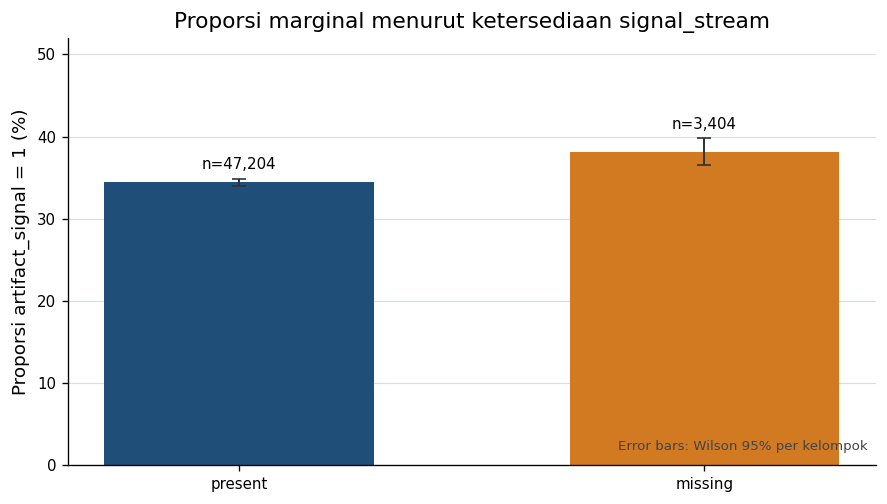

In [12]:
eda_marginal_rows = []
for eda_availability in ('present', 'missing'):
    eda_part = eda_analysis.loc[eda_analysis.availability.eq(eda_availability)]
    eda_successes, eda_n = (int(eda_part.artifact_signal.sum()), int(len(eda_part)))
    eda_low, eda_high = wilson_interval(eda_successes, eda_n)
    eda_marginal_rows.append({'Ketersediaan': eda_availability, 'artifact_signal = 1 (n)': eda_successes, 'Denominator (n)': eda_n, 'Proporsi (%)': 100 * eda_successes / eda_n, 'Wilson 95% bawah (%)': 100 * eda_low, 'Wilson 95% atas (%)': 100 * eda_high})
eda_marginal = pd.DataFrame(eda_marginal_rows)
eda_marginal_indexed = eda_marginal.set_index('Ketersediaan')
eda_marginal_gap_pp = eda_marginal_indexed.loc['missing', 'Proporsi (%)'] - eda_marginal_indexed.loc['present', 'Proporsi (%)']
display(eda_marginal.round(2))
display(Markdown(f"Proporsi artifact pada Train adalah **{eda_marginal_indexed.loc['present', 'Proporsi (%)']:.2f}%** saat stream tersedia dan **{eda_marginal_indexed.loc['missing', 'Proporsi (%)']:.2f}%** saat missing. Selisih missing − present adalah **{eda_marginal_gap_pp:+.2f} poin persentase (pp)**."))
eda_fig, eda_ax = plt.subplots(figsize=(7.5, 4.3))
eda_x = np.arange(len(eda_marginal))
eda_rates = eda_marginal['Proporsi (%)'].to_numpy()
eda_lower = eda_rates - eda_marginal['Wilson 95% bawah (%)'].to_numpy()
eda_upper = eda_marginal['Wilson 95% atas (%)'].to_numpy() - eda_rates
eda_ax.bar(eda_x, eda_rates, color=[eda_COLORS[eda_name] for eda_name in eda_marginal['Ketersediaan']], width=0.58, zorder=2)
eda_ax.errorbar(eda_x, eda_rates, yerr=np.vstack([eda_lower, eda_upper]), fmt='none', ecolor='#30343b', capsize=4, lw=1.2, zorder=3)
for eda_i, eda_row in eda_marginal.iterrows():
    eda_ax.text(eda_i, eda_row['Wilson 95% atas (%)'] + 1.2, f"n={int(eda_row['Denominator (n)']):,}", ha='center', fontsize=9)
eda_ax.set_xticks(eda_x, eda_marginal['Ketersediaan'])
eda_ax.set_ylabel('Proporsi artifact_signal = 1 (%)')
eda_ax.set_title('Proporsi marginal menurut ketersediaan signal_stream')
eda_ax.set_ylim(0, 52)
eda_ax.grid(axis='y', color='#d9dde3', linewidth=0.7, zorder=0)
eda_ax.text(0.99, 0.03, 'Error bars: Wilson 95% per kelompok', transform=eda_ax.transAxes, ha='right', va='bottom', fontsize=8, color='#40444b')
eda_fig.tight_layout()
plt.show()

Label 1 lebih sering muncul pada kelompok kosong, dengan selisih +3,66 pp. Ini belum memperhitungkan perbedaan waktu dan volume laporan.

### EDA 4. Perubahan sepanjang waktu

,Present n,Present (%),Missing n,Missing (%),Gap missing − present (pp)
period,,,,,
47–57,12537,30.78,1009,28.94,-1.84
58–68,15664,40.37,1072,50.37,10.01
69–79,19003,32.05,1323,35.22,3.18


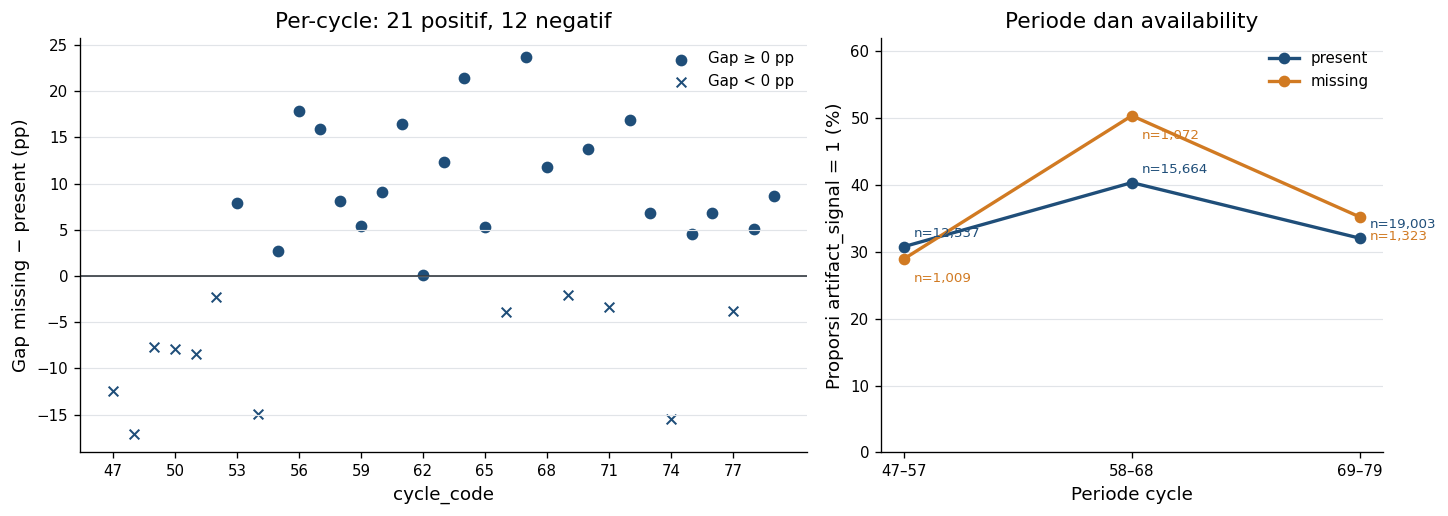

Gap per periode ialah **-1.84 pp**, **+10.01 pp**, dan **+3.18 pp**. Pada cycle dengan n≥20 untuk masing-masing status, 21/33 gap positif dan 12/33 negatif; rentangnya -17.04 sampai +23.73 pp.

In [13]:
eda_period_prevalence = prevalence_table(eda_analysis, ['period', 'availability'])
eda_period_pivot = eda_period_prevalence.pivot(index='period', columns='availability', values='prevalence').loc[['47–57', '58–68', '69–79']]
eda_period_n = eda_period_prevalence.pivot(index='period', columns='availability', values='n').loc[eda_period_pivot.index]
eda_period_summary = pd.DataFrame({'Present n': eda_period_n['present'].astype(int), 'Present (%)': 100 * eda_period_pivot['present'], 'Missing n': eda_period_n['missing'].astype(int), 'Missing (%)': 100 * eda_period_pivot['missing'], 'Gap missing − present (pp)': 100 * (eda_period_pivot['missing'] - eda_period_pivot['present'])})
display(eda_period_summary.round(2))
eda_cycle_prevalence = prevalence_table(eda_analysis, ['cycle_code', 'availability'])
eda_cycle_rates = eda_cycle_prevalence.pivot(index='cycle_code', columns='availability', values='prevalence')
eda_cycle_n = eda_cycle_prevalence.pivot(index='cycle_code', columns='availability', values='n')
eda_cycle_gap = 100 * (eda_cycle_rates['missing'] - eda_cycle_rates['present'])
eda_cycle_supported = eda_cycle_n['missing'].ge(20) & eda_cycle_n['present'].ge(20)
assert eda_cycle_supported.all(), 'Exact-cycle graph must not include unsupported groups'
eda_positive_cycles = int((eda_cycle_gap > 0).sum())
eda_negative_cycles = int((eda_cycle_gap < 0).sum())
eda_fig, (eda_ax_cycle, eda_ax_period) = plt.subplots(1, 2, figsize=(12.2, 4.4), gridspec_kw={'width_ratios': [1.45, 1]})
for eda_marker, eda_condition, eda_label in [('o', eda_cycle_gap >= 0, 'Gap ≥ 0 pp'), ('x', eda_cycle_gap < 0, 'Gap < 0 pp')]:
    eda_ax_cycle.scatter(eda_cycle_gap.index[eda_condition], eda_cycle_gap.loc[eda_condition], marker=eda_marker, s=34, color=eda_COLORS['present'], label=eda_label, linewidths=1.2)
eda_ax_cycle.axhline(0, color='#343a40', lw=1)
eda_ax_cycle.set_xticks(np.arange(47, 80, 3))
eda_ax_cycle.set_xlabel('cycle_code')
eda_ax_cycle.set_ylabel('Gap missing − present (pp)')
eda_ax_cycle.set_title(f'Per-cycle: {eda_positive_cycles} positif, {eda_negative_cycles} negatif')
eda_ax_cycle.legend(frameon=False, loc='best')
eda_ax_cycle.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_period_x = np.arange(len(eda_period_pivot))
for eda_availability in ('present', 'missing'):
    eda_values = 100 * eda_period_pivot[eda_availability].to_numpy()
    eda_ax_period.plot(eda_period_x, eda_values, marker='o', lw=2, color=eda_COLORS[eda_availability], label=eda_availability)
    for eda_j, (eda_value, eda_n) in enumerate(zip(eda_values, eda_period_n[eda_availability].to_numpy())):
        eda_offset = (6, 6) if eda_availability == 'present' else (6, -14)
        eda_ax_period.annotate(f'n={int(eda_n):,}', (eda_j, eda_value), xytext=eda_offset, textcoords='offset points', fontsize=8, color=eda_COLORS[eda_availability])
eda_ax_period.set_xticks(eda_period_x, eda_period_pivot.index)
eda_ax_period.set_xlabel('Periode cycle')
eda_ax_period.set_ylabel('Proporsi artifact_signal = 1 (%)')
eda_ax_period.set_title('Periode dan availability')
eda_ax_period.set_ylim(0, 62)
eda_ax_period.legend(frameon=False)
eda_ax_period.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_fig.tight_layout()
plt.show()
display(Markdown(f"Gap per periode ialah **{eda_period_summary.iloc[0]['Gap missing − present (pp)']:+.2f} pp**, **{eda_period_summary.iloc[1]['Gap missing − present (pp)']:+.2f} pp**, dan **{eda_period_summary.iloc[2]['Gap missing − present (pp)']:+.2f} pp**. Pada cycle dengan n≥20 untuk masing-masing status, {eda_positive_cycles}/{len(eda_cycle_gap)} gap positif dan {eda_negative_cycles}/{len(eda_cycle_gap)} negatif; rentangnya {eda_cycle_gap.min():+.2f} sampai {eda_cycle_gap.max():+.2f} pp."))

Gap positif pada 21 dari 33 cycle, tetapi negatif pada 12 lainnya. Periode tengah menunjukkan perbedaan terbesar; satu angka agregat menyembunyikan variasi ini.

### EDA 5. Perbedaan volume

,n,minimum,q1,median,q3,maximum
availability,,,,,,
present,47204,20.65,27.70,31.78,36.92,98.06
missing,3404,16.34,20.55,21.81,23.79,77.52


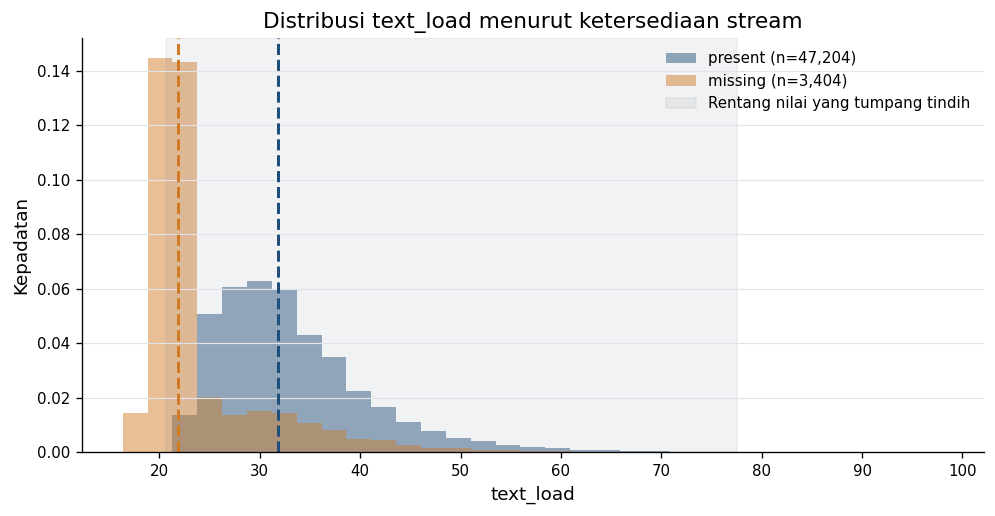

Median text_load adalah **31.78** saat stream tersedia dan **21.81** saat missing. Rentang nilai yang sama-sama teramati adalah **20.65–77.52**; di luarnya terdapat 906 baris missing dan 65 baris present.

In [14]:
eda_text_summary = eda_analysis.groupby('availability')['text_load'].agg(n='size', minimum='min', q1=lambda eda_x: eda_x.quantile(0.25), median='median', q3=lambda eda_x: eda_x.quantile(0.75), maximum='max').loc[['present', 'missing']]
eda_overlap_low = max(eda_text_summary.loc['present', 'minimum'], eda_text_summary.loc['missing', 'minimum'])
eda_overlap_high = min(eda_text_summary.loc['present', 'maximum'], eda_text_summary.loc['missing', 'maximum'])
eda_outside_missing = int((eda_analysis.availability.eq('missing') & ~eda_analysis.text_load.between(eda_overlap_low, eda_overlap_high)).sum())
eda_outside_present = int((eda_analysis.availability.eq('present') & ~eda_analysis.text_load.between(eda_overlap_low, eda_overlap_high)).sum())
display(eda_text_summary.round(2))
eda_fig, eda_ax = plt.subplots(figsize=(8.4, 4.4))
eda_bins = np.linspace(eda_analysis.text_load.min(), eda_analysis.text_load.max(), 34)
for eda_availability in ('present', 'missing'):
    eda_values = eda_analysis.loc[eda_analysis.availability.eq(eda_availability), 'text_load']
    eda_ax.hist(eda_values, bins=eda_bins, density=True, alpha=0.48, color=eda_COLORS[eda_availability], label=f'{eda_availability} (n={len(eda_values):,})')
    eda_ax.axvline(eda_values.median(), color=eda_COLORS[eda_availability], lw=1.8, linestyle='--')
eda_ax.axvspan(eda_overlap_low, eda_overlap_high, color='#78828f', alpha=0.1, label='Rentang nilai yang tumpang tindih')
eda_ax.set_xlabel('text_load')
eda_ax.set_ylabel('Kepadatan')
eda_ax.set_title('Distribusi text_load menurut ketersediaan stream')
eda_ax.legend(frameon=False)
eda_ax.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_fig.tight_layout()
plt.show()
display(Markdown(f"Median text_load adalah **{eda_text_summary.loc['present', 'median']:.2f}** saat stream tersedia dan **{eda_text_summary.loc['missing', 'median']:.2f}** saat missing. Rentang nilai yang sama-sama teramati adalah **{eda_overlap_low:.2f}–{eda_overlap_high:.2f}**; di luarnya terdapat {eda_outside_missing:,} baris missing dan {eda_outside_present:,} baris present."))

Median `text_load` kelompok kosong 21,81, sedangkan kelompok terisi 31,78. Komposisi volume yang berbeda menjadi alasan untuk membandingkan kelompok waktu/volume yang lebih setara.

### EDA 6. Menyamakan komposisi

Bandingkan hasil awal dengan penyesuaian setiap cycle serta tiga periode x 5/10 kelompok volume. **Gap = persentase kosong - terisi**, dalam poin persentase (pp). Coverage menunjukkan bagian data yang memenuhi minimum support.

In [15]:
eda_cycle_standardized, eda_cycle_cells = standardized_contrast(eda_analysis, ['cycle_code'], min_support=20)
eda_q5_frame, eda_q5_edges = add_global_quantile_bins(eda_analysis, 5)
eda_period_q5, eda_period_q5_cells = standardized_contrast(eda_q5_frame, ['period', 'text_load_q5'], min_support=20)
eda_q10_frame, eda_q10_edges = add_global_quantile_bins(eda_analysis, 10)
eda_period_q10, eda_period_q10_cells = standardized_contrast(eda_q10_frame, ['period', 'text_load_q10'], min_support=20)
eda_comparison_rows = [{'Kontras': 'Marginal (seluruh Train)', 'Present (%)': eda_marginal_indexed.loc['present', 'Proporsi (%)'], 'Missing (%)': eda_marginal_indexed.loc['missing', 'Proporsi (%)'], 'Gap missing − present (pp)': eda_marginal_gap_pp, 'Sel didukung': '—', 'Baris present tercakup': int(eda_analysis.availability.eq('present').sum()), 'Baris missing tercakup': int(eda_analysis.availability.eq('missing').sum()), 'Coverage keseluruhan (%)': 100.0}]
for eda_label, eda_result in [('Exact cycle', eda_cycle_standardized), ('Periode × kuantil text_load (5)', eda_period_q5), ('Periode × kuantil text_load (10)', eda_period_q10)]:
    eda_comparison_rows.append({'Kontras': eda_label, 'Present (%)': 100 * eda_result['standardized_prevalence']['present'], 'Missing (%)': 100 * eda_result['standardized_prevalence']['missing'], 'Gap missing − present (pp)': eda_result['standardized_missing_minus_present_pp'], 'Sel didukung': f"{eda_result['cells_supported']}/{eda_result['cells_total']}", 'Baris present tercakup': eda_result['covered_rows_by_availability']['present'], 'Baris missing tercakup': eda_result['covered_rows_by_availability']['missing'], 'Coverage keseluruhan (%)': 100 * eda_result['coverage_all_rows']})
eda_contrasts = pd.DataFrame(eda_comparison_rows)
display(eda_contrasts.round(2))
eda_support_by_group = pd.DataFrame([{'Kontras': 'Exact cycle', 'Coverage present (%)': 100 * eda_cycle_standardized['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_cycle_standardized['coverage_by_availability']['missing']}, {'Kontras': 'Periode × kuantil 5', 'Coverage present (%)': 100 * eda_period_q5['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_period_q5['coverage_by_availability']['missing']}, {'Kontras': 'Periode × kuantil 10', 'Coverage present (%)': 100 * eda_period_q10['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_period_q10['coverage_by_availability']['missing']}])
display(eda_support_by_group.round(2))
print(f'Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin={len(eda_q5_edges) - 1}; 10-bin={len(eda_q10_edges) - 1}.')

,Kontras,Present (%),Missing (%),Gap missing − present (pp),Sel didukung,Baris present tercakup,Baris missing tercakup,Coverage keseluruhan (%)
0,Marginal (seluruh Train),34.47,38.13,3.66,—,47204,3404,100.00
1,Exact cycle,34.47,38.43,3.96,33/33,47204,3404,100.00
2,Periode × kuantil text_load (5),35.17,32.87,-2.30,15/15,47204,3404,100.00
3,Periode × kuantil text_load (10),35.52,33.36,-2.15,28/30,44368,3372,94.33


,Kontras,Coverage present (%),Coverage missing (%)
0,Exact cycle,100.00,100.00
1,Periode × kuantil 5,100.00,100.00
2,Periode × kuantil 10,93.99,99.06


Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin=5; 10-bin=10.


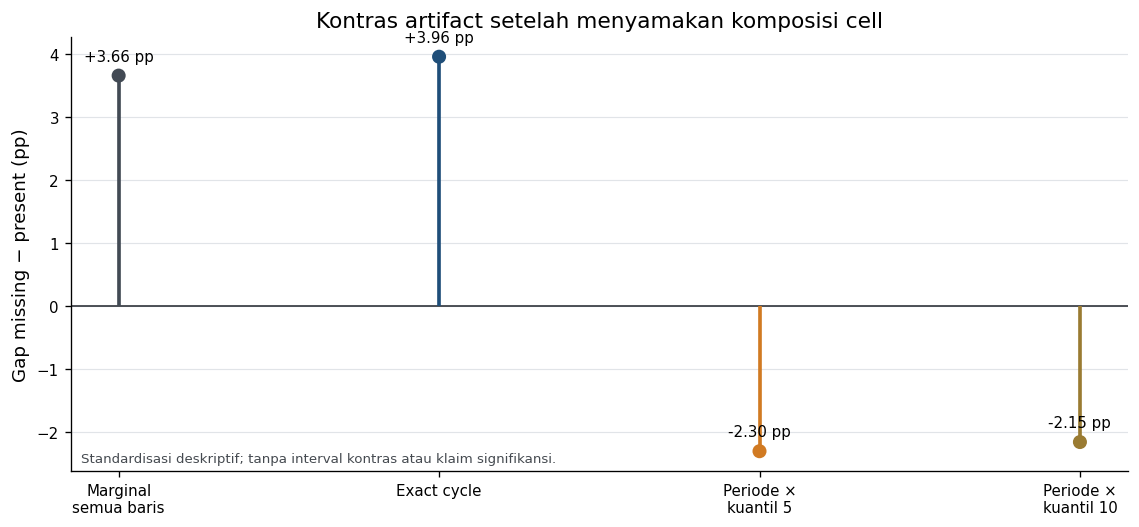

In [16]:
eda_fig, eda_ax = plt.subplots(figsize=(9.6, 4.5))
eda_labels = ['Marginal\nsemua baris', 'Exact cycle', 'Periode ×\nkuantil 5', 'Periode ×\nkuantil 10']
eda_gaps = eda_contrasts['Gap missing − present (pp)'].to_numpy()
eda_colors = ['#424a54', '#1f4e79', '#d17a22', '#9a7b32']
eda_x = np.arange(len(eda_gaps))
eda_ax.axhline(0, color='#30343b', lw=1)
eda_ax.vlines(eda_x, 0, eda_gaps, color=eda_colors, lw=2.2)
eda_ax.scatter(eda_x, eda_gaps, color=eda_colors, s=55, zorder=3)
for eda_i, eda_row in eda_contrasts.iterrows():
    eda_value = eda_row['Gap missing − present (pp)']
    eda_ax.annotate(f'{eda_value:+.2f} pp', (eda_i, eda_value), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9)
eda_ax.set_xticks(eda_x, eda_labels)
eda_ax.set_ylabel('Gap missing − present (pp)')
eda_ax.set_title('Kontras artifact setelah menyamakan komposisi cell')
eda_ax.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_ax.text(0.01, 0.02, 'Standardisasi deskriptif; tanpa interval kontras atau klaim signifikansi.', transform=eda_ax.transAxes, fontsize=8, color='#454a50')
eda_fig.tight_layout()
plt.show()

Menyamakan cycle saja tidak membalik arah gap, sedangkan penyesuaian periode dan volume membalikkannya. Hasil 5 dan 10 kelompok memiliki arah serupa, dengan coverage lebih rendah pada 10 kelompok.

### EDA 7. Interpretasi dan batasan

In [17]:
display(Markdown('\n\n'.join([
    f"Gap awal {eda_marginal_gap_pp:+.2f} pp; setelah penyesuaian cycle {eda_cycle_standardized['standardized_missing_minus_present_pp']:+.2f} pp; periode dan volume {eda_period_q5['standardized_missing_minus_present_pp']:+.2f} pp (5 kelompok) dan {eda_period_q10['standardized_missing_minus_present_pp']:+.2f} pp (10 kelompok).",
    f"Minimum 20 baris per status/kelompok. Pemeriksaan 10 kelompok mencakup {eda_period_q10['supported_rows_total']:,}/{len(eda_analysis):,} baris ({eda_period_q10['coverage_all_rows']:.2%}); {eda_period_q10['cells_supported']}/{eda_period_q10['cells_total']} kelompok didukung.",
    "Kelompok volume masih kasar dan faktor lain belum dikontrol. Routing berasal dari diagnosis model terdahulu; hasil EDA ini tidak membuktikan bahwa status teks menyebabkan label atau kenaikan performa."
])))

Gap awal +3.66 pp; setelah penyesuaian cycle +3.96 pp; periode dan volume -2.30 pp (5 kelompok) dan -2.15 pp (10 kelompok).

Minimum 20 baris per status/kelompok. Pemeriksaan 10 kelompok mencakup 47,740/50,608 baris (94.33%); 28/30 kelompok didukung.

Kelompok volume masih kasar dan faktor lain belum dikontrol. Routing berasal dari diagnosis model terdahulu; hasil EDA ini tidak membuktikan bahwa status teks menyebabkan label atau kenaikan performa.

### EDA 8. Kesimpulan

Ada perbedaan proporsi label, tetapi arahnya bergantung pada cara laporan dibandingkan. Pada seluruh data, teks kosong memiliki proporsi label 1 **38,13%**, dibanding **34,47%** pada teks terisi: gap **+3,66 pp**. Setelah komposisi setiap cycle disamakan, gap tetap positif **+3,96 pp** dengan seluruh **33 cycle dan 100% baris** didukung.

Ketika periode dan kelompok volume disamakan bersama, gap berbalik menjadi **-2,30 pp** pada 5 kelompok volume (**100% coverage**) dan **-2,15 pp** pada 10 kelompok (**94,33% coverage; 28/30 strata**). Jadi, pembalikan arah muncul pada penyesuaian gabungan waktu dan volume, bukan pada waktu saja.

Status teks kosong tidak cukup untuk menyimpulkan proporsi artifact tanpa memperhatikan komposisi laporan. Penyesuaian masih memakai rentang volume yang kasar; hasil ini bersifat deskriptif, tidak membuktikan sebab-akibat, dan belum memastikan pola yang sama pada Test.

## 4. Perkembangan pendekatan

MAE mengukur rata-rata selisih absolut; median menjadi baseline yang sesuai. TP1 memiliki target diskret yang terkonsentrasi, sedangkan TP2 memiliki **34.333 nilai unik**. Karena itu, multiclass per nilai target TP1 tidak disalin.

Tabel berikut adalah hasil historis enam window temporal. Primary mengevaluasi horizon 4 cycle, sedangkan H12 horizon 12 cycle. Pooled MAE menimbang baris, equal-cycle menimbang cycle. H12 memakai ulang baris primary dan bukan replikasi independen.

### Asal hasil perbandingan

Tabel historis merangkum eksperimen sebelumnya dan disertakan langsung di notebook. Tabel ini menjadi pembanding; evaluasi temporal di bagian berikut tetap dilatih dan dihitung ulang dari data mentah.

In [18]:
HISTORICAL_REGRESSION = {'round1': {'aggregate': {'primary': {'R0_A': {'raw': {'mae': 24.99995439255727}},
                                      'R0_B': {'raw': {'mae': 15.561566673577277}},
                                      'R0_C': {'raw': {'mae': 15.311399701979889}},
                                      'R1_A': {'raw': {'mae': 15.622633297651307}},
                                      'R1_B': {'raw': {'mae': 15.571019136538627}},
                                      'R1_C': {'raw': {'mae': 15.148985650926262}},
                                      'R1_D': {'raw': {'mae': 13.349836350894211}}},
                          'secondary': {'R0_A': {'raw': {'mae': 24.999953235461803}},
                                        'R0_B': {'raw': {'mae': 15.940477432103245}},
                                        'R0_C': {'raw': {'mae': 15.674229658183892}},
                                        'R1_A': {'raw': {'mae': 15.83497986243071}},
                                        'R1_B': {'raw': {'mae': 15.898887106553621}},
                                        'R1_C': {'raw': {'mae': 15.477893321106137}},
                                        'R1_D': {'raw': {'mae': 15.577240029210996}}}}},
 'research_records': [{'Recipe': 'hybrid_ridge',
                       'Policy': 'inner',
                       'Primary MAE': 12.551304697152961,
                       'Equal-cycle MAE': 12.790073160003772,
                       'H12 MAE': 13.938115395708403,
                       'H12_E': 16.39545540608638,
                       'H12_L': 11.859080899055558,
                       'EF0': 13.7676827037216,
                       'EF1': 10.02465283789459,
                       'Low tail': 10.831680779387,
                       'High tail': 9.551670866978435,
                       'Missing': 14.369609629816512,
                       'Present': 12.421130020218591},
                      {'Recipe': 'svd_hgb',
                       'Policy': 'inner',
                       'Primary MAE': 12.36618114115671,
                       'Equal-cycle MAE': 12.67774260401219,
                       'H12 MAE': 14.714120448143928,
                       'H12_E': 17.27256119171744,
                       'H12_L': 12.54954959467325,
                       'EF0': 13.477161473153624,
                       'EF1': 10.058460591885932,
                       'Low tail': 13.424663694185218,
                       'High tail': 10.229859413704485,
                       'Missing': 13.354497567994125,
                       'Present': 12.295426357808006},
                      {'Recipe': 'lgb_inner',
                       'Policy': 'inner',
                       'Primary MAE': 13.064889419500766,
                       'Equal-cycle MAE': 13.322505244690326,
                       'H12 MAE': 15.604152895892863,
                       'H12_E': 17.88658787869114,
                       'H12_L': 13.673096938815528,
                       'EF0': 14.24851748462536,
                       'EF1': 10.606265508785821,
                       'Low tail': 15.169253810839319,
                       'High tail': 10.474778209986246,
                       'Missing': 12.730073875720919,
                       'Present': 13.088859274315107},
                      {'Recipe': 'structured_ridge',
                       'Policy': 'inner',
                       'Primary MAE': 14.178654387001835,
                       'Equal-cycle MAE': 14.332997251819961,
                       'H12 MAE': 15.20581754330597,
                       'H12_E': 17.2292421592208,
                       'H12_L': 13.493897515919771,
                       'EF0': 15.60152008222906,
                       'EF1': 11.223087749898268,
                       'Low tail': 16.24683365173298,
                       'High tail': 11.931332096766294,
                       'Missing': 14.218475076878011,
                       'Present': 14.1758035750468},
                      {'Recipe': 'lgb_text',
                       'Policy': 'inner',
                       'Primary MAE': 11.931600241417073,
                       'Equal-cycle MAE': 12.283547721814166,
                       'H12 MAE': 14.704040710404005,
                       'H12_E': 17.473256695250942,
                       'H12_L': 12.3611432941471,
                       'EF0': 12.979046674204357,
                       'EF1': 9.75585186173262,
                       'Low tail': 12.235391007294663,
                       'High tail': 9.49544128641078,
                       'Missing': 13.041812852718394,
                       'Present': 11.85211876094124}],
 'stage5': {'jobs': [{'window': 'W1',
                      'policy': 'inner',
                      'raw': {'mae': 16.40578123979536, 'n': 4114},
                      'prediction_sha256': '479e630a8eb2e4ac1fdcce4fffd2d9b7f2d51ad798a5b8065bec7b02b6502655'},
                     {'window': 'W2',
                      'policy': 'inner',
                      'raw': {'mae': 12.042870406642555, 'n': 6493},
                      'prediction_sha256': '228ba0a0a225b7f1aaba9e0c4a2b0068ca2d86e2d7016aedec09079fb8d626cc'},
                     {'window': 'W3',
                      'policy': 'inner',
                      'raw': {'mae': 12.354210396236708, 'n': 7078},
                      'prediction_sha256': 'ed318f97c043fbc6fa32618eb23529a0fc5b2b82396659a48c42ec138c972392'},
                     {'window': 'W4',
                      'policy': 'inner',
                      'raw': {'mae': 11.999389350917381, 'n': 4950},
                      'prediction_sha256': 'bbaf8da4d0d9effc3cea53fc527f4e0681bbd9cdabb0c73467be51d549451fc7'},
                     {'window': 'W5',
                      'policy': 'inner',
                      'raw': {'mae': 10.774911088464474, 'n': 7462},
                      'prediction_sha256': '1982e0df808884f75393f3a0eb682e4cf16d15c0489abbe00c1aad468c0aba66'},
                     {'window': 'W6',
                      'policy': 'inner',
                      'raw': {'mae': 10.303425218611173, 'n': 8491},
                      'prediction_sha256': '5c7eadad8122fbc6c2576d369fc1d54c96a768142a267ab57341b57ee6b7072e'},
                     {'window': 'H12_E',
                      'policy': 'inner',
                      'raw': {'mae': 17.473256695250942, 'n': 17685},
                      'prediction_sha256': '1d71ec700786926598eddca41613b43475cafa86c143e93d1f23f202c14524ed'},
                     {'window': 'H12_L',
                      'policy': 'inner',
                      'raw': {'mae': 12.3611432941471, 'n': 20903},
                      'prediction_sha256': '550c719d861aa7ab67bbc24b595610eff7f35099964e5f2b84381836702e0074'}],
            'aggregate': {'primary': {'lgb_text__inner': {'per_cycle': [{'cycle': 56,
                                                                         'mae': 16.011234859514477},
                                                                        {'cycle': 57,
                                                                         'mae': 16.945248130548663},
                                                                        {'cycle': 58,
                                                                         'mae': 17.269775713331533},
                                                                        {'cycle': 59,
                                                                         'mae': 15.438640002602774},
                                                                        {'cycle': 60,
                                                                         'mae': 11.846295881483124},
                                                                        {'cycle': 61,
                                                                         'mae': 11.707499306578177},
                                                                        {'cycle': 62,
                                                                         'mae': 12.23605842105882},
                                                                        {'cycle': 63,
                                                                         'mae': 12.333938256810534},
                                                                        {'cycle': 64,
                                                                         'mae': 12.43579147111728},
                                                                        {'cycle': 65,
                                                                         'mae': 11.091598842665157},
                                                                        {'cycle': 66,
                                                                         'mae': 12.558683602736494},
                                                                        {'cycle': 67,
                                                                         'mae': 13.1084667800341},
                                                                        {'cycle': 68,
                                                                         'mae': 10.962860035589374},
                                                                        {'cycle': 69,
                                                                         'mae': 12.183176180062379},
                                                                        {'cycle': 70,
                                                                         'mae': 12.655542315777648},
                                                                        {'cycle': 71,
                                                                         'mae': 11.612560409352009},
                                                                        {'cycle': 72,
                                                                         'mae': 10.87040269642365},
                                                                        {'cycle': 73,
                                                                         'mae': 10.965463239302517},
                                                                        {'cycle': 74,
                                                                         'mae': 11.02840820857086},
                                                                        {'cycle': 75,
                                                                         'mae': 10.268515012091166},
                                                                        {'cycle': 76,
                                                                         'mae': 10.570958380716744},
                                                                        {'cycle': 77,
                                                                         'mae': 10.081566547699524},
                                                                        {'cycle': 78,
                                                                         'mae': 10.388220471516561},
                                                                        {'cycle': 79,
                                                                         'mae': 10.234240557956408}]}}}},
 'provenance': {'reports/round1/results.json': '2d92c744d9dc3076664f2fea312504e147baa2f931fbd22a2c17ff5fe321b376',
                'reports/regression_round2/results.json': '75e7d54ed58f414a271409481a59337fd030bb391e6d65941137dff67f0345ac',
                'reports/regression_research/report_data.json': 'd1681c17c1938e21668205f15a582bc90d1db419e5033de606502252b0104f95',
                'reports/regression_research/stage5_lgb_text.json': 'a7fb69f80c4aa0d91c01f50669b2e921dd51e1f04a7a91153ad6e71565837cf5'}}

r1 = HISTORICAL_REGRESSION["round1"]
model_names = {"R0_A": "Global median", "R0_B": "Median impact", "R0_C": "Median impact + EF",
               "R1_A": "Standardized OLS", "R1_B": "HGB squared error",
               "R1_C": "HGB two features, MAE", "R1_D": "HGB expanded, MAE"}
evolution = pd.DataFrame([{"approach": model_names[k],
                           "primary MAE": r1["aggregate"]["primary"][k]["raw"]["mae"],
                           "H12 MAE": r1["aggregate"]["secondary"][k]["raw"]["mae"]}
                          for k in model_names])
display(evolution.round(5))
research = pd.DataFrame(HISTORICAL_REGRESSION["research_records"])
selected = research[(research.Policy == "inner") & research.Recipe.isin(
    ["structured_ridge", "hybrid_ridge", "svd_hgb", "lgb_inner", "lgb_text"])].copy()
display(selected[["Recipe", "Primary MAE", "Equal-cycle MAE", "H12 MAE", "H12_E", "H12_L"]].round(5))
print("Historical table provenance SHA-256:")
for source_name, source_hash in HISTORICAL_REGRESSION["provenance"].items():
    print(" ", source_name, source_hash)

,approach,primary MAE,H12 MAE
0,Global median,24.99995,24.99995
1,Median impact,15.56157,15.94048
2,Median impact + EF,15.31140,15.67423
3,Standardized OLS,15.62263,15.83498
4,HGB squared error,15.57102,15.89889
5,"HGB two features, MAE",15.14899,15.47789
6,"HGB expanded, MAE",13.34984,15.57724


,Recipe,Primary MAE,Equal-cycle MAE,H12 MAE,H12_E,H12_L
0,hybrid_ridge,12.55130,12.79007,13.93812,16.39546,11.85908
1,svd_hgb,12.36618,12.67774,14.71412,17.27256,12.54955
2,lgb_inner,13.06489,13.32251,15.60415,17.88659,13.67310
3,structured_ridge,14.17865,14.33300,15.20582,17.22924,13.49390
4,lgb_text,11.93160,12.28355,14.70404,17.47326,12.36114


Historical table provenance SHA-256:
  reports/round1/results.json 2d92c744d9dc3076664f2fea312504e147baa2f931fbd22a2c17ff5fe321b376
  reports/regression_round2/results.json 75e7d54ed58f414a271409481a59337fd030bb391e6d65941137dff67f0345ac
  reports/regression_research/report_data.json d1681c17c1938e21668205f15a582bc90d1db419e5033de606502252b0104f95
  reports/regression_research/stage5_lgb_text.json a7fb69f80c4aa0d91c01f50669b2e921dd51e1f04a7a91153ad6e71565837cf5


Global median menghasilkan MAE **25,0000**. Median menurut impact dan entry friction menurunkannya menjadi **15,3114**, menunjukkan bahwa informasi fitur memberi baseline yang jauh lebih baik. HGB dua fitur dengan objective MAE mencapai **15,1490**; fitur structured yang diperluas mencapai **13,3498** pada primary.

Perluasan fitur belum selalu membantu: H12 HGB meningkat dari **15,4779 menjadi 15,5772**, yaitu memburuk. Karena recency dan penghapusan fitur juga tidak konsisten, langkah berikutnya menambahkan informasi teks. Structured Ridge **14,1787** menjadi hybrid Ridge **12,5513** pada primary; perbandingan satu keluarga ini mendukung manfaat prediktif teks.

HGB+SVD mencapai **12,3662**, lalu LightGBM+SVD memberi primary terbaik **11,9316**. Namun hybrid Ridge tetap lebih baik pada H12 (**13,9381 vs 14,7040**). LightGBM dipilih dengan menerima trade-off horizon tersebut, bukan karena unggul pada setiap kondisi.

,window,MAE,n
0,W1,16.40578,4114
1,W2,12.04287,6493
2,W3,12.35421,7078
3,W4,11.99939,4950
4,W5,10.77491,7462
5,W6,10.30343,8491
6,H12_E,17.47326,17685
7,H12_L,12.36114,20903


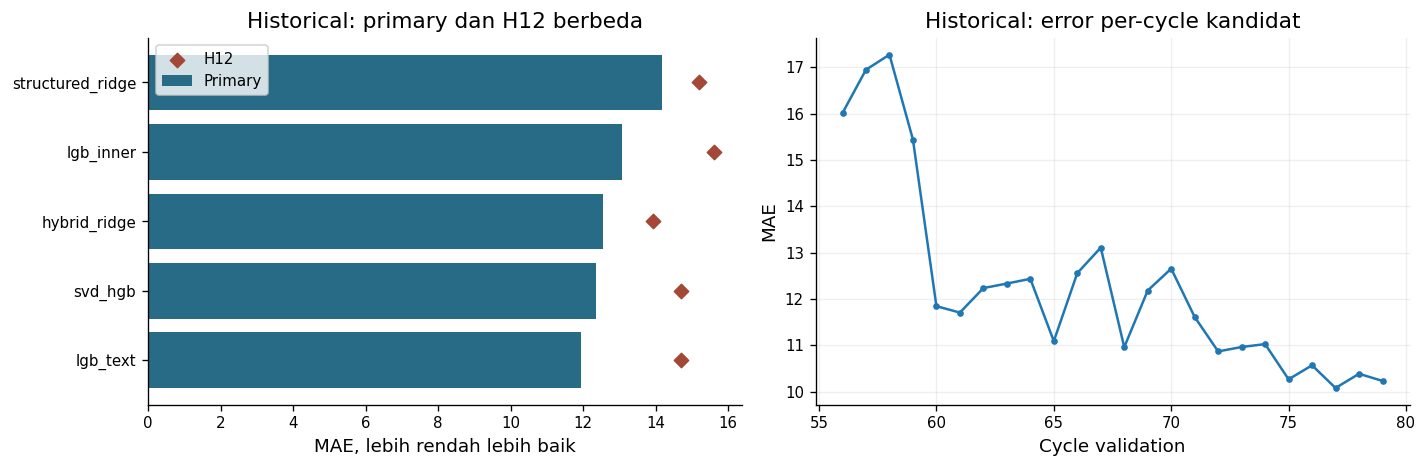

In [19]:
stage5 = HISTORICAL_REGRESSION["stage5"]
window_rows = []
for j in stage5['jobs']:
    if j['policy'] == 'inner':
        window_rows.append({'window': j['window'], 'MAE': j['raw']['mae'], 'n': j['raw']['n']})
windows = pd.DataFrame(window_rows)
display(windows.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = selected.sort_values('Primary MAE')
axes[0].barh(order.Recipe, order['Primary MAE'], color='#276b86', label='Primary')
axes[0].scatter(order['H12 MAE'], order.Recipe, color='#a34837', marker='D', label='H12')
axes[0].set(title='Historical: primary dan H12 berbeda', xlabel='MAE, lebih rendah lebih baik'); axes[0].legend()
pc = pd.DataFrame(stage5['aggregate']['primary']['lgb_text__inner']['per_cycle'])
axes[1].plot(pc.cycle, pc.mae, '-o', markersize=3)
axes[1].set(title='Historical: error per-cycle kandidat', xlabel='Cycle validation', ylabel='MAE')
axes[1].grid(alpha=.2); fig.tight_layout(); plt.show()

## 5. Pipeline dan validasi

1. Parser numerik; imputasi median dan encoding kategori dari fit fold. Unknown category -1 diperlakukan LightGBM sebagai missing.
2. TF-IDF unigram-bigram, maksimal 20.000 fitur, `min_df=2`; SVD32 (`n_iter=7`, seed 42).
3. LightGBM `regression_l1`, 400 trees, learning rate 0,05; dua konfigurasi frozen: base (31 leaves/minleaf40/L2=1), regularized (15/80/3).
4. Inner MAE memilih konfigurasi dan alpha dari {0; 0,25; 0,50; 0,75; 1}.

Rank blend: `clip((1-alpha)*raw + alpha*100*average_rank(raw)/n_cycle, 0, 100)`. Rank berasal dari prediksi, bukan label; baris dalam satu cycle harus diprediksi bersama. Mapping mengubah jarak, bukan urutan prediksi.

**Inner:** 47-71 -> 72-75. **Outer:** refit 47-75 -> evaluasi 76-79. Semua preprocessing dibangun ulang per fit.

In [20]:
def rank_blend(raw, cycles, weight):
    frame = pd.DataFrame({'p': np.asarray(raw, float), 'c': np.asarray(cycles)})
    if not np.isfinite(frame.p).all() or frame.c.isna().any():
        raise ValueError('Prediksi dan cycle harus finite/lengkap.')
    percentile = (100 * frame.groupby('c').p.rank(method='average') /
                  frame.groupby('c').p.transform('size')).to_numpy()
    return np.clip((1-weight)*frame.p.to_numpy() + weight*percentile, 0, 100)

def fit_predict(params_id, fit_frame, predict_frame):
    model = build_lgb_text(params_id)
    with threadpool_limits(limits=2):
        model.fit(fit_frame[features], fit_frame.threat_rank.to_numpy())
        raw = model.predict(predict_frame[features])
    assert model.audit_state()['fit_rows'] == len(fit_frame)
    return model, raw

inner_train = train[train.cycle_code <= 71].copy()
inner_valid = train[train.cycle_code.between(72, 75)].copy()
outer_train = train[train.cycle_code <= 75].copy()
outer_valid = train[train.cycle_code.between(76, 79)].copy()
assert inner_train.cycle_code.max() < inner_valid.cycle_code.min()
assert outer_train.cycle_code.max() < outer_valid.cycle_code.min()
assert not set(outer_train.record_id) & set(outer_valid.record_id)
choices = []
start = time.perf_counter()
for param in ['base', 'regularized']:
    _, raw = fit_predict(param, inner_train, inner_valid)
    for alpha in [0., .25, .5, .75, 1.]:
        mapped = rank_blend(raw, inner_valid.cycle_code, alpha)
        choices.append({'param': param, 'rank_weight': alpha,
                        'MAE inner': mean_absolute_error(inner_valid.threat_rank, mapped)})
inner_choices = pd.DataFrame(choices).sort_values(['MAE inner', 'param', 'rank_weight'], kind='stable')
chosen = inner_choices.iloc[0]
display(inner_choices.reset_index(drop=True).round(6))
print('Keputusan W6 hanya dari inner:', chosen.param, float(chosen.rank_weight))

,param,rank_weight,MAE inner
0,base,0.50,10.730048
1,base,0.25,10.774911
2,base,0.75,10.774975
3,base,0.00,10.895443
4,base,1.00,10.914513
5,regularized,0.50,11.115188
6,regularized,0.25,11.153189
7,regularized,0.75,11.165096
8,regularized,0.00,11.276842
9,regularized,1.00,11.315294


Keputusan W6 hanya dari inner: base 0.5


In [21]:
outer_model, outer_raw = fit_predict(chosen.param, outer_train, outer_valid)
outer_prediction = rank_blend(outer_raw, outer_valid.cycle_code, float(chosen.rank_weight))
y_outer = outer_valid.threat_rank.to_numpy()
baseline_models = [
    {'id':'R0_A','kind':'global_median','features':'two'},
    {'id':'R0_C','kind':'joint_median','features':'two'}]
baseline_rows = []
for recipe in baseline_models:
    baseline = build_round1_model(recipe)
    names = [] if recipe['kind']=='global_median' else ['impact_load','entry_friction']
    with threadpool_limits(limits=2):
        baseline.fit(outer_train[names], outer_train.threat_rank.to_numpy())
        baseline_pred = baseline.predict(outer_valid[names])
    baseline_rows.append({'recipe':recipe['id'],'MAE W6':mean_absolute_error(y_outer,baseline_pred)})
display(pd.DataFrame(baseline_rows).round(5))
error = outer_prediction - y_outer
w6_metrics = {'n': len(y_outer), 'MAE': float(np.abs(error).mean()),
              'RMSE': float(np.sqrt(np.mean(error**2))), 'bias pred-actual': float(error.mean())}
expected_w6 = next(j for j in stage5['jobs'] if j['window'] == 'W6' and j['policy'] == 'inner')
assert np.isclose(w6_metrics['MAE'], expected_w6['raw']['mae'], rtol=0, atol=1e-8), 'Reproduksi W6 berbeda; selidiki environment/input.'
assert array_digest(outer_prediction) == expected_w6['prediction_sha256']
display(pd.DataFrame([w6_metrics], index=['Dihitung ulang: W6 76–79']))
core_receipt = {'task':'regression','fit_cycles':[47,75],'validation_cycles':[76,79],
    'fit_rows':len(outer_train),'validation_rows':len(outer_valid),'inner_choice':{
        'param':str(chosen.param),'rank_weight':float(chosen.rank_weight)},
    'metrics':w6_metrics,'prediction_sha256':array_digest(outer_prediction),
    'matches_historical_predictions':True,'historical_primary_mae':float(selected.loc[selected.Recipe.eq('lgb_text'), 'Primary MAE'].iloc[0]),
    'historical_h12_mae':float(selected.loc[selected.Recipe.eq('lgb_text'), 'H12 MAE'].iloc[0]),'kaggle_public_mae':11.71363,
    'fit_preprocessing_only_train':True,'test_used_in_core':False,'baseline_metrics':baseline_rows}
display(pd.Series(core_receipt, name='W6 replay receipt'))
print('CORE_RECEIPT_JSON=' + json.dumps(core_receipt, sort_keys=True))
w6_by_cycle = pd.DataFrame({'cycle': outer_valid.cycle_code.to_numpy(), 'abs_error': abs(error)}).groupby('cycle').agg(n=('abs_error','size'), MAE=('abs_error','mean'))
display(w6_by_cycle)
print('Equal-cycle W6:', w6_by_cycle.MAE.mean(), '| total detik training demonstrasi:', round(time.perf_counter()-start, 1))
from sklearn.metrics import mean_squared_error, r2_score
independent_mae = float(mean_absolute_error(y_outer, outer_prediction))
independent_rmse = float(np.sqrt(mean_squared_error(y_outer, outer_prediction)))
independent_r2 = float(r2_score(y_outer, outer_prediction))
assert np.isclose(independent_mae, w6_metrics["MAE"], rtol=0, atol=1e-12)
assert np.isclose(independent_rmse, w6_metrics["RMSE"], rtol=0, atol=1e-12)
assert np.isfinite(independent_r2)
assert np.array_equal(outer_prediction, np.clip(outer_prediction, 0, 100))
independent_metrics = {"MAE": independent_mae, "RMSE": independent_rmse, "R2": independent_r2}
display(pd.Series(independent_metrics, name="Independent sklearn metrics"))
print("INDEPENDENT_METRICS_JSON=" + json.dumps(independent_metrics, sort_keys=True))


,recipe,MAE W6
0,R0_A,25.00000
1,R0_C,14.96965


,n,MAE,RMSE,bias pred-actual
Dihitung ulang: W6 76–79,8491,10.303425,14.193912,-0.46194


task                                                                     regression
fit_cycles                                                                 [47, 75]
validation_cycles                                                          [76, 79]
fit_rows                                                                      42117
validation_rows                                                                8491
inner_choice                                  {'param': 'base', 'rank_weight': 0.5}
metrics                           {'n': 8491, 'MAE': 10.303425218611173, 'RMSE':...
prediction_sha256                 5c7eadad8122fbc6c2576d369fc1d54c96a768142a267a...
matches_historical_predictions                                                 True
historical_primary_mae                                                      11.9316
historical_h12_mae                                                        14.704041
kaggle_public_mae                                                          1

CORE_RECEIPT_JSON={"baseline_metrics": [{"MAE W6": 25.00000064774467, "recipe": "R0_A"}, {"MAE W6": 14.969652838299375, "recipe": "R0_C"}], "fit_cycles": [47, 75], "fit_preprocessing_only_train": true, "fit_rows": 42117, "historical_h12_mae": 14.704040710404005, "historical_primary_mae": 11.931600241417073, "inner_choice": {"param": "base", "rank_weight": 0.5}, "kaggle_public_mae": 11.71363, "matches_historical_predictions": true, "metrics": {"MAE": 10.303425218611173, "RMSE": 14.193911908446832, "bias pred-actual": -0.4619403639722759, "n": 8491}, "prediction_sha256": "5c7eadad8122fbc6c2576d369fc1d54c96a768142a267ab57341b57ee6b7072e", "task": "regression", "test_used_in_core": false, "validation_cycles": [76, 79], "validation_rows": 8491}


,n,MAE
cycle,,
76,1822,10.570958
77,2335,10.081567
78,2146,10.388220
79,2188,10.234241


Equal-cycle W6: 10.31874648947231 | total detik training demonstrasi: 43.6


MAE     10.303425
RMSE    14.193912
R2       0.758233
Name: Independent sklearn metrics, dtype: float64

INDEPENDENT_METRICS_JSON={"MAE": 10.303425218611173, "R2": 0.7582326003625546, "RMSE": 14.193911908446832}


## 6. Evaluasi model

W6 dihitung ulang di atas; angka primary/H12 berasal dari eksperimen historis. LightGBM+text memberi **MAE 11,93160 primary / 14,70404 H12**. Namun **hybrid Ridge lebih baik pada H12: 13,93812**. Model terpilih tidak mendominasi semua horizon.

Seluruh window sudah digunakan dalam development; reproduksi W6 bukan holdout baru.

,kelompok,n,MAE W6,bias W6
0,Semua,8491,10.30343,-0.46194
1,EF0,5738,11.49037,-1.12429
2,EF1,2753,7.82950,0.91857
3,Target ≤5,442,8.44707,8.17898
4,Target ≥95,434,5.97580,-5.34055
5,Stream missing,526,12.88477,3.97574
6,Stream present,7965,10.13296,-0.75500


,Recipe,Primary MAE,EF0,EF1,Low tail,High tail,Missing,Present
0,hybrid_ridge,12.5513,13.76768,10.02465,10.83168,9.55167,14.36961,12.42113
4,lgb_text,11.9316,12.97905,9.75585,12.23539,9.49544,13.04181,11.85212


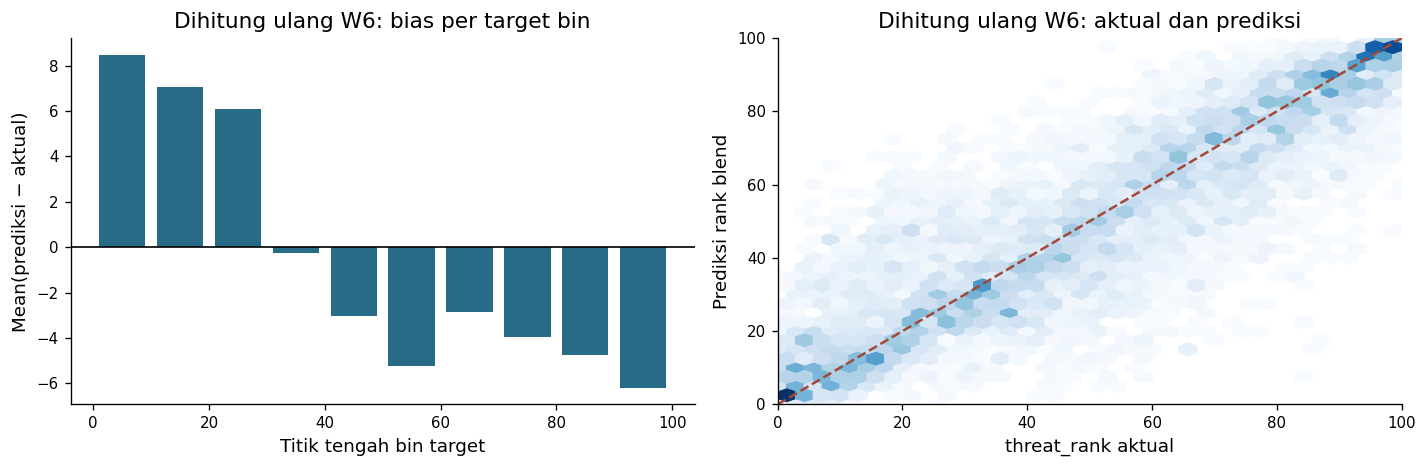

In [22]:
masks = {'Semua': np.ones(len(outer_valid), bool),
         'EF0': outer_valid.entry_friction.eq(0).to_numpy(),
         'EF1': outer_valid.entry_friction.eq(1).to_numpy(),
         'Target ≤5': y_outer <= 5, 'Target ≥95': y_outer >= 95,
         'Stream missing': stream_missing_mask(outer_valid),
         'Stream present': ~stream_missing_mask(outer_valid)}
fresh_subgroups = pd.DataFrame([{'kelompok': name, 'n': int(mask.sum()),
      'MAE W6': float(abs(error[mask]).mean()) if mask.any() else np.nan,
      'bias W6': float(error[mask].mean()) if mask.any() else np.nan}
      for name, mask in masks.items()])
display(fresh_subgroups.round(5))
display(selected[selected.Recipe.isin(['hybrid_ridge', 'lgb_text'])][
    ['Recipe', 'Primary MAE', 'EF0', 'EF1', 'Low tail', 'High tail', 'Missing', 'Present']].round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = pd.cut(y_outer, np.arange(0, 101, 10), include_lowest=True)
grouped = pd.DataFrame({'bin': bins, 'err': error}).groupby('bin', observed=True).err.mean()
axes[0].bar(np.arange(len(grouped))*10+5, grouped, width=8, color='#276b86')
axes[0].axhline(0, color='black', lw=1)
axes[0].set(title='Dihitung ulang W6: bias per target bin', xlabel='Titik tengah bin target', ylabel='Mean(prediksi − aktual)')
axes[1].hexbin(y_outer, outer_prediction, gridsize=35, mincnt=1, cmap='Blues')
axes[1].plot([0,100], [0,100], '--', color='#a34837')
axes[1].set(title='Dihitung ulang W6: aktual dan prediksi', xlabel='threat_rank aktual', ylabel='Prediksi rank blend', xlim=(0,100), ylim=(0,100))
fig.tight_layout(); plt.show()

Pada grafik bias, target rendah cenderung diprediksi terlalu tinggi dan target tinggi terlalu rendah. Prediksi mendekati nilai tengah dapat memberi MAE yang baik secara keseluruhan, tetapi masih kurang tepat pada target ekstrem.

Sebagian Test memiliki nilai count nol tanpa analog Train; maknanya belum diketahui. Tanpa label Test, risikonya belum dapat diukur. Banyaknya eksperimen juga membatasi kekuatan kesimpulan generalisasi.

## 7. Melatih model akhir dan membuat prediksi Test

Evaluasi sebelumnya memisahkan data masa lalu untuk melatih model dan cycle berikutnya untuk mengukur error. Setelah pendekatan dipilih, model dilatih ulang memakai **seluruh 50.608 baris Train**, agar prediksi official Test memanfaatkan semua label yang tersedia. Tahap inilah yang disebut **refit penuh**.

Sel di bawah menjalankannya jika `RUN_FULL_TRAIN = True`: seluruh preprocessing dipelajari ulang dari Train, kemudian model memprediksi Test dan menyimpan CSV lokal. Nilainya dibiarkan `False` saat demonstrasi agar tidak mengulang pembuatan file; **evaluasi temporal di bagian sebelumnya tetap dijalankan**.

Tahap ini tidak menghasilkan skor validasi baru karena label Test tidak tersedia. Angka public Kaggle yang ditampilkan berasal dari submission historis, bukan dihitung oleh sel ini.

In [23]:
RUN_FULL_TRAIN = False
if RUN_FULL_TRAIN:
    assert files['test'] and files['sample'], 'Official Test dan SampleSubmission diperlukan untuk inference.'
    assert sha(files['test']) == '4e6c381d582ed24f92d17f620f4f0ad25e2e0def29eb57a91a5482867f6afe3c'
    assert sha(files['sample']) == '63a51f4b7dfbb0eec9800099407abd8be14d25ec18a533cd39dc854ffc190a32'
    test = pd.read_csv(files['test']); sample = pd.read_csv(files['sample'])
    assert test.shape == (29421, 18) and 'threat_rank' not in test
    assert set(test.columns) == set(train.columns) - {'threat_rank'}
    assert test.record_id.is_unique and not set(train.record_id) & set(test.record_id)
    assert test.cycle_code.between(80, 91).all()
    assert sample.columns.tolist() == ['record_id','threat_rank'] and sample.record_id.equals(test.record_id)
    deployment_choices = []
    for param in ['base', 'regularized']:
        if param == chosen.param:
            raw = outer_raw
        else:
            _, raw = fit_predict(param, outer_train, outer_valid)
        for alpha in [0., .25, .5, .75, 1.]:
            p = rank_blend(raw, outer_valid.cycle_code, alpha)
            deployment_choices.append({'param': param, 'alpha': alpha,
                'mae': mean_absolute_error(y_outer, p)})
    deployment = sorted(deployment_choices, key=lambda d: (d['mae'], d['param'], d['alpha']))[0]
    assert deployment['param'] == 'base' and deployment['alpha'] == .5
    final_model, test_raw = fit_predict(deployment['param'], train, test)
    test_prediction = rank_blend(test_raw, test.cycle_code, deployment['alpha'])
    output = sample.copy()
    output['threat_rank'] = test_prediction
    assert len(output) == 29421 and output.record_id.is_unique
    assert output.record_id.equals(test.record_id) and np.isfinite(test_prediction).all()
    assert output.threat_rank.between(0, 100).all()
    destination = Path(os.environ.get('SAMUEL_REGRESSION_PREDICTION_PATH', Path.cwd() / 'regression_reproduced.csv')).expanduser()
    if not destination.is_absolute(): destination = Path.cwd() / destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    csv_bytes = output.to_csv(index=False, float_format='%.17g').encode('utf-8')
    if destination.exists() and destination.read_bytes() != csv_bytes:
        raise FileExistsError('Output sebelumnya berbeda; periksa sebelum mengganti file.')
    destination.write_bytes(csv_bytes)
    print('Refit:', final_model.audit_state()['fit_rows'], 'baris | CSV:', len(output), 'baris')
    print('Deployment:', deployment, '| SHA-256:', sha(destination))
    print('CSV lokal siap diperiksa; tidak ada upload otomatis.')
else:
    print('Refit/inference final belum dijalankan pada eksekusi ini. Aktifkan RUN_FULL_TRAIN jika diperlukan.')

Refit/inference final belum dijalankan pada eksekusi ini. Aktifkan RUN_FULL_TRAIN jika diperlukan.


## 8. Kesimpulan

EDA menunjukkan bahwa perbandingan proporsi artifact pada teks kosong dan terisi dipengaruhi waktu serta volume laporan. Gap awal **+3,66 pp** berubah menjadi sekitar **-2,2 sampai -2,3 pp** setelah penyesuaian. Analisis ini memakai target Classification; manfaat teks untuk prediksi `threat_rank` harus dinilai melalui eksperimen Regression tersendiri.

Dalam eksperimen Regression, fitur structured memperbaiki baseline median, kemudian tambahan teks kembali menurunkan MAE. LightGBM L1 dengan TF-IDF/SVD32 dan inner-selected rank blend dipilih karena mencapai **primary MAE 11,9316**. Rank blend menyesuaikan jarak prediksi dalam setiap cycle tanpa menggunakan label inference.

Pilihan tersebut memiliki trade-off. H12 LightGBM adalah **14,7040**, sedangkan hybrid Ridge lebih baik pada **13,9381**. Prediksi juga masih terlalu tinggi pada target rendah dan terlalu rendah pada target tinggi. Karena itu, rata-rata MAE yang baik belum berarti error sudah merata pada semua horizon dan kelompok target.

Public benchmark approach individual ini adalah **11,71363**, terpisah dari validasi internal. Seluruh window telah digunakan dalam development, dan label Test belum tersedia; hasil tidak menjamin private generalization. EDA dan evaluasi model bersama-sama membantu menjelaskan data, alasan pemilihan pendekatan, serta keterbatasan keputusan tersebut.